# AnaeCare: 3-class (normal / leve / moderada) | ONE notebook, all 3 modalities (unas, yemas, palmas)
Methodology adapted from Kato et al., *Br J Haematol* 2024:
- **Non-CNN baseline**: mean R,G,B per image -> linear model (multinomial Logistic Regression for class output)
- **CNN model**: ImageNet-pretrained EfficientNet-B0 -> GeM pooling -> FC, AdamW (lr 1e-3), Cosine Annealing, Albumentations (flip, affine, elastic/grid, coarse dropout, Gaussian/motion blur)
- **5-fold CV split by participant**, SAME folds for all 3 modalities (fair comparison); frame predictions averaged per participant
- **Grad-CAM** for every modality

Flow: Config -> index data -> run unas -> run yemas -> run palmas -> **final metrics, results, comparison**.

**Checkpoints:** saved under `CKPT_ROOT`. If anything is interrupted, re-run the same cell; finished folds/modalities are skipped, an unfinished fold resumes from its last epoch.

## Cell 1: Install and imports

In [1]:
!pip install -q timm albumentations

In [2]:
import os, re, json, random, time, shutil, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve, auc)
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| timm", timm.__version__, "| albumentations", A.__version__, "| device:", DEVICE)

torch 2.11.0+cu128 | timm 1.0.29 | albumentations 2.0.8 | device: cuda


## Cell 2: Config

In [3]:
MANUAL_PATHS = {
    "csv": "/kaggle/input/datasets/shimu080/dataset2/Dataset2.csv",
    "metadata": "/kaggle/input/datasets/shimu080/metadata/metadata.csv",
    "yemas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames",
    "palmas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames",
    "unas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images",
}

MODALITIES = ["unas", "yemas", "palmas"]
CLASS_NAMES = ["normal", "leve", "moderada"]
CLASS_ALIAS = {"normal": 0, "leve": 1, "moderada": 2, "moderado": 2}
LABELS = [0, 1, 2]; N_CLASSES = 3
PC = [f"p{i}" for i in LABELS]

# frames used per participant (yemas has 32 and palmas 16 near-identical frames; more frames = slower)
MAX_FRAMES = {"unas": 999, "yemas": 8, "palmas": 8}

IMG_SIZE = 224
N_FOLDS = 5              # paper: five-fold CV
EPOCHS = 40              # paper: 60
PATIENCE = 10            # early stopping on validation macro-F1
BATCH_SIZE = 32          # paper: 32
LR = 1e-3                # paper: 1e-3 (try 3e-4 if unstable)
WEIGHT_DECAY = 1e-2
BACKBONE = "efficientnet_b0"
NUM_WORKERS = 2
SEED = 42
USE_AMP = torch.cuda.is_available()

WORK = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
CKPT_ROOT = f"{WORK}/ckpt_all"              # checkpoints (per modality sub-folder)
MET_ROOT = f"{WORK}/metrics_all"            # metrics / plots (per modality sub-folder + ALL_modalities)
ALL_OUT = f"{MET_ROOT}/ALL_modalities"
for d in [CKPT_ROOT, MET_ROOT, ALL_OUT] + [f"{CKPT_ROOT}/{m}" for m in MODALITIES] + [f"{MET_ROOT}/{m}" for m in MODALITIES]:
    os.makedirs(d, exist_ok=True)

# If the Kaggle session ended earlier: add the old notebook output as an input dataset and put the path of its
# "ckpt_all" folder here, e.g. "/kaggle/input/my-old-output/ckpt_all". Missing files are copied once.
RESUME_FROM = None
if RESUME_FROM and os.path.isdir(RESUME_FROM):
    for r, _, fs in os.walk(RESUME_FROM):
        for f in fs:
            dst = os.path.join(CKPT_ROOT, os.path.relpath(os.path.join(r, f), RESUME_FROM))
            if not os.path.exists(dst):
                os.makedirs(os.path.dirname(dst), exist_ok=True); shutil.copy(os.path.join(r, f), dst)
    print("Copied old checkpoints from", RESUME_FROM)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(SEED)
print("Checkpoints:", CKPT_ROOT, "| Metrics:", MET_ROOT)

Checkpoints: /kaggle/working/ckpt_all | Metrics: /kaggle/working/metrics_all


## Cell 3: Check input paths and CSV files

In [4]:
for k, p in MANUAL_PATHS.items():
    print(f"{k:9s} exists={os.path.exists(p)}  {p}")
for m in MODALITIES:
    r0 = MANUAL_PATHS[m]
    ext = {}
    for r, _, fs in os.walk(r0):
        for f in fs:
            e = os.path.splitext(f)[1].lower(); ext[e] = ext.get(e, 0) + 1
    print(f"\n{m}: top level = {sorted(os.listdir(r0))[:10]} | files = {ext}")
for name in ["metadata", "csv"]:
    try:
        d = pd.read_csv(MANUAL_PATHS[name]); print(f"\n{name}: shape={d.shape} columns={list(d.columns)}"); display(d.head(3))
    except Exception as e:
        print(f"\n{name}: could not read ({e})")

csv       exists=True  /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
metadata  exists=True  /kaggle/input/datasets/shimu080/metadata/metadata.csv
yemas     exists=True  /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
palmas    exists=True  /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
unas      exists=True  /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images

unas: top level = ['Leve', 'Moderada', 'Normal'] | files = {'.jpg': 826}

yemas: top level = ['Leve', 'Moderada', 'Normal'] | files = {'.jpg': 26816}

palmas: top level = ['Leve', 'Moderada', 'Normal'] | files = {'.jpg': 13328}

metadata: shape=(909, 22) columns=['ID', 'Sexo', 'Edad', 'Fatiga', 'Debilidad', 'Latidos irregulares', 'Dificultad para respirar', 'Mareos o aturdimiento', 'Dolor en el pecho', 'Manos y pies fríos', 'Dolores de cabeza', 'Normal', 'Leve', 'Moderado', 'Frecuencia Cardiaca', 'Hemoglobina', 'Oxígeno', 'Peso', 'Talla', 'YE

,ID,Sexo,Edad,Fatiga,Debilidad,Latidos irregulares,Dificultad para respirar,Mareos o aturdimiento,Dolor en el pecho,Manos y pies fríos,...,Leve,Moderado,Frecuencia Cardiaca,Hemoglobina,Oxígeno,Peso,Talla,YEMAS,PALMAS,UNAS
0,ID001,M,25,0,0,1,0,0,0,0,...,0,0,70.0,13.6,98,89.0,183.0,20230706_211043.mp4,20230706_211218.mp4,20230706_211246.jpg
1,ID002,M,25,1,1,0,0,0,0,0,...,0,0,77.0,13.7,98,76.0,165.0,NaN,NaN,NaN
2,ID003,M,23,0,0,0,0,1,0,0,...,0,0,66.0,14.3,98,64.8,159.0,20230706_205929.mp4,20230706_210050.mp4,20230706_210140.jpg



csv: shape=(999, 7) columns=['ID', 'Class', 'Anemia Predict', 'Split', 'YEMAS Path', 'PALMAS Path', 'UNAS Path']


,ID,Class,Anemia Predict,Split,YEMAS Path,PALMAS Path,UNAS Path
0,ID001,Normal,0,train,dataset/yemas/Normal/20230706_211043.mp4,dataset/palmas/Normal/20230706_211218.mp4,dataset/unas/Normal/20230706_211246.jpg
1,ID002,Normal,0,train,NaN,NaN,NaN
2,ID003,Normal,0,train,dataset/yemas/Normal/20230706_205929.mp4,dataset/palmas/Normal/20230706_210050.mp4,dataset/unas/Normal/20230706_210140.jpg


## Cell 4: Index all modalities + ONE participant-level 5-fold split shared by all modalities

In [5]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def parse_label(parts):
    for p in reversed(parts):
        if p.lower() in CLASS_ALIAS: return CLASS_ALIAS[p.lower()]
    return None

def parse_id(parts):
    for p in reversed(parts):
        m = re.search(r"(ID\s*_?\d+)", p, re.I)
        if m: return re.sub(r"[\s_]", "", m.group(1)).upper()
    return None

def build_index(mod):
    r0, rows = MANUAL_PATHS[mod], []
    for r, _, fs in os.walk(r0):
        for f in fs:
            if os.path.splitext(f)[1].lower() in IMG_EXT:
                full = os.path.join(r, f); rel = Path(os.path.relpath(full, r0)).parts
                rows.append((full, parse_id(rel), parse_label(rel)))
    d = pd.DataFrame(rows, columns=["path", "id", "label"])
    miss = int(d.id.isna().sum() + d.label.isna().sum())
    d = d.dropna(subset=["id", "label"]).copy(); d["label"] = d.label.astype(int)
    return d.sort_values("path").reset_index(drop=True), miss

def subsample(d, k):
    out = []
    for _, g in d.groupby("id"):
        g = g.sort_values("path"); idx = np.linspace(0, len(g) - 1, min(len(g), k)).round().astype(int)
        out.append(g.iloc[np.unique(idx)])
    return pd.concat(out).reset_index(drop=True)

index_all = {}
for m in MODALITIES:
    d, miss = build_index(m); index_all[m] = d
    pp = d.groupby("id").label.first()
    print(f"{m:7s}: {len(d)} images | {d.id.nunique()} participants | rows without id/label: {miss} | "
          f"{dict(pp.map(dict(enumerate(CLASS_NAMES))).value_counts())} | "
          f"images/participant max {d.groupby('id').size().max()}")
    assert d.groupby("id").label.nunique().max() == 1, "a participant has 2 different labels"

# one label table for ALL participants (union over modalities)
allp = pd.concat([d.groupby("id").label.first().reset_index() for d in index_all.values()])
assert allp.groupby("id").label.nunique().max() == 1, "same participant has different labels across modalities"
allp = allp.drop_duplicates("id").reset_index(drop=True)

SPLIT_FILE = f"{CKPT_ROOT}/folds_global.json"
if os.path.exists(SPLIT_FILE):
    fold_of = json.load(open(SPLIT_FILE)); print("Loaded saved split")
else:
    fold_of = {}
    for k, (_, te) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(allp.id, allp.label)):
        for pid in allp.id.iloc[te]: fold_of[pid] = k
    json.dump(fold_of, open(SPLIT_FILE, "w")); print("Created and saved split")

dfs = {}
for m in MODALITIES:
    d = subsample(index_all[m], MAX_FRAMES[m]); d["fold"] = d.id.map(fold_of); dfs[m] = d
    print(f"{m:7s}: using {len(d)} images")
print("\nParticipants per fold x class (union of all modalities):")
print(pd.crosstab(allp.id.map(fold_of), allp.label.map(dict(enumerate(CLASS_NAMES)))))

unas   : 826 images | 823 participants | rows without id/label: 0 | {'normal': np.int64(550), 'leve': np.int64(200), 'moderada': np.int64(73)} | images/participant max 2
yemas  : 26816 images | 834 participants | rows without id/label: 0 | {'normal': np.int64(558), 'leve': np.int64(201), 'moderada': np.int64(75)} | images/participant max 64
palmas : 13328 images | 829 participants | rows without id/label: 0 | {'normal': np.int64(554), 'leve': np.int64(201), 'moderada': np.int64(74)} | images/participant max 32
Created and saved split
unas   : using 826 images
yemas  : using 6672 images
palmas : using 6632 images

Participants per fold x class (union of all modalities):
label  leve  moderada  normal
id                           
0        40        15     113
1        41        15     112
2        41        15     112
3        40        16     112
4        40        15     112


## Cell 5: Samples from each modality

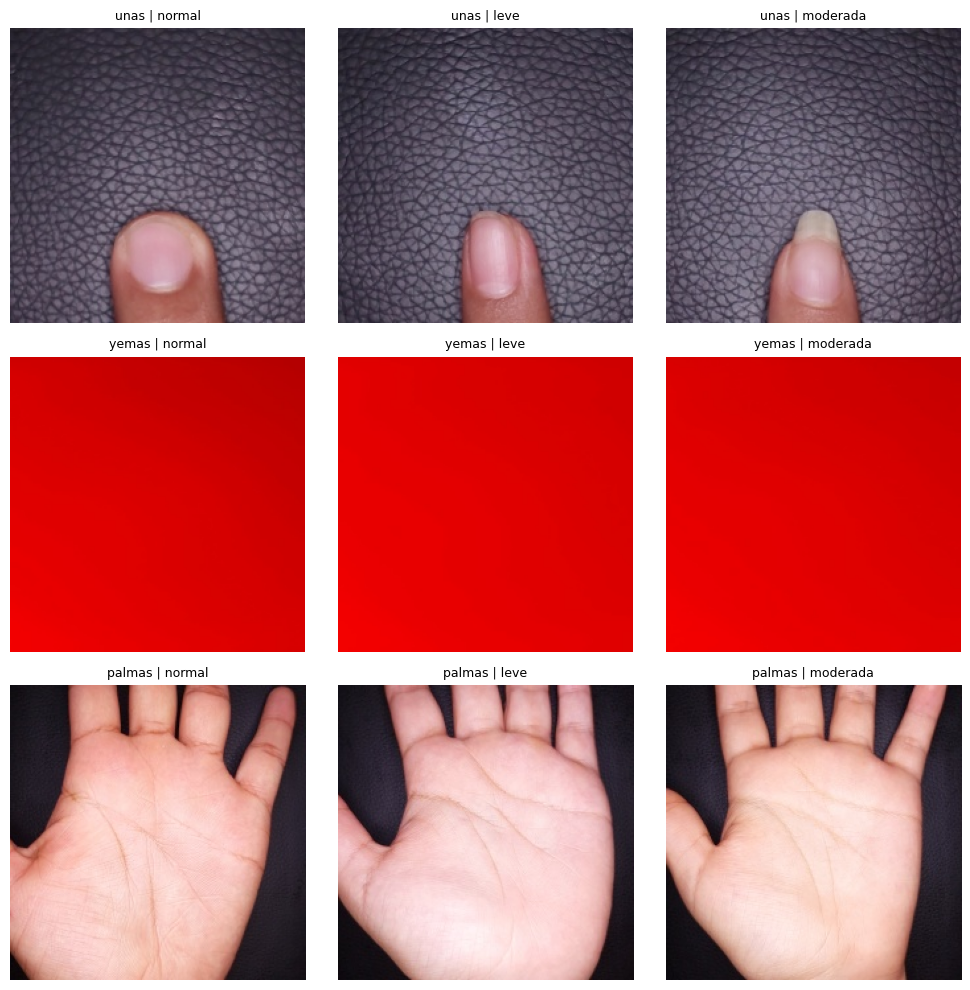

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i, m in enumerate(MODALITIES):
    for c in LABELS:
        p = dfs[m][dfs[m].label == c].sample(1, random_state=SEED).path.iloc[0]
        axes[i, c].imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)); axes[i, c].axis("off")
        axes[i, c].set_title(f"{m} | {CLASS_NAMES[c]}", fontsize=9)
plt.tight_layout(); plt.show()

## Cell 6: Metric helpers + export (Accuracy, Precision, Recall, F1, ROC-AUC, Confusion matrix)

In [7]:
def aggregate_by_participant(d):
    # average of softmax probabilities of all frames of one participant (paper: average of left/right eye)
    return d.groupby("id").agg({**{c: "mean" for c in PC}, "y": "first"}).reset_index()

def compute_metrics(y, prob):
    pred = prob.argmax(1)
    kw = dict(labels=LABELS, zero_division=0)
    return {
        "accuracy": accuracy_score(y, pred),
        "precision_macro": precision_score(y, pred, average="macro", **kw),
        "recall_macro": recall_score(y, pred, average="macro", **kw),
        "f1_macro": f1_score(y, pred, average="macro", **kw),
        "precision_weighted": precision_score(y, pred, average="weighted", **kw),
        "recall_weighted": recall_score(y, pred, average="weighted", **kw),
        "f1_weighted": f1_score(y, pred, average="weighted", **kw),
        "roc_auc_ovr_macro": roc_auc_score(y, prob, multi_class="ovr", average="macro", labels=LABELS),
    }

def export_all(name, g, title, out_dir):
    y, prob = g.y.values, g[PC].values; pred = prob.argmax(1); yb = label_binarize(y, classes=LABELS)
    m = compute_metrics(y, prob)
    pd.Series(m, name="value").to_csv(f"{out_dir}/{name}_overall_metrics.csv")
    rep = pd.DataFrame(classification_report(y, pred, labels=LABELS, target_names=CLASS_NAMES,
                                             output_dict=True, zero_division=0)).T
    rep["roc_auc_ovr"] = np.nan
    for i, c in enumerate(CLASS_NAMES): rep.loc[c, "roc_auc_ovr"] = roc_auc_score(yb[:, i], prob[:, i])
    rep.to_csv(f"{out_dir}/{name}_per_class_report.csv")
    cm = confusion_matrix(y, pred, labels=LABELS); cmn = cm / cm.sum(1, keepdims=True)
    idx, col = [f"true_{c}" for c in CLASS_NAMES], [f"pred_{c}" for c in CLASS_NAMES]
    pd.DataFrame(cm, index=idx, columns=col).to_csv(f"{out_dir}/{name}_confusion_matrix_counts.csv")
    pd.DataFrame(cmn, index=idx, columns=col).round(4).to_csv(f"{out_dir}/{name}_confusion_matrix_normalised.csv")

    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
    for a, mat, t, fmt in [(ax[0], cm, "Confusion matrix (counts)", "d"), (ax[1], cmn, "Confusion matrix (row-normalised)", ".2f")]:
        a.imshow(mat, cmap="Blues"); a.set_title(t)
        a.set_xticks(LABELS); a.set_xticklabels(CLASS_NAMES); a.set_yticks(LABELS); a.set_yticklabels(CLASS_NAMES)
        a.set_xlabel("Predicted"); a.set_ylabel("True")
        for i in LABELS:
            for j in LABELS:
                a.text(j, i, format(mat[i, j], fmt), ha="center", va="center", color="white" if mat[i, j] > mat.max() / 2 else "black")
    for i in LABELS:
        fpr, tpr, _ = roc_curve(yb[:, i], prob[:, i]); ax[2].plot(fpr, tpr, label=f"{CLASS_NAMES[i]} (AUC={auc(fpr, tpr):.3f})")
    ax[2].plot([0, 1], [0, 1], "k--"); ax[2].set_title(f"ROC one-vs-rest (macro AUC={m['roc_auc_ovr_macro']:.3f})")
    ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate"); ax[2].legend()
    fig.suptitle(title); plt.tight_layout(); plt.savefig(f"{out_dir}/{name}_report.png", dpi=200); plt.close()

    p = g.copy(); p["true_class"] = [CLASS_NAMES[i] for i in y]; p["pred_class"] = [CLASS_NAMES[i] for i in pred]
    p["correct"] = (y == pred).astype(int); p.to_csv(f"{out_dir}/{name}_participant_predictions.csv", index=False)
    return m, cm

## Cell 7: Dataset, augmentation, model (CNN -> GeM -> FC)

In [8]:
def coarse_dropout():
    try: return A.CoarseDropout(num_holes_range=(1, 6), hole_height_range=(8, 32), hole_width_range=(8, 32), p=0.3)
    except Exception: return A.CoarseDropout(max_holes=6, max_height=32, max_width=32, p=0.3)

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
train_tfms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE), A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-15, 15), p=0.5),
    A.OneOf([A.ElasticTransform(p=1.0), A.GridDistortion(p=1.0)], p=0.3),
    coarse_dropout(),
    A.OneOf([A.GaussianBlur(blur_limit=(3, 5), p=1.0), A.MotionBlur(blur_limit=5, p=1.0)], p=0.3),
    A.Normalize(mean=MEAN, std=STD), ToTensorV2()])
eval_tfms = A.Compose([A.Resize(IMG_SIZE, IMG_SIZE), A.Normalize(mean=MEAN, std=STD), ToTensorV2()])

class ImgDS(Dataset):
    def __init__(self, d, tfms): self.paths, self.y, self.tfms = d.path.values, d.label.values, tfms
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        im = cv2.cvtColor(cv2.imread(self.paths[i]), cv2.COLOR_BGR2RGB)
        return self.tfms(image=im)["image"], int(self.y[i])

def make_loader(d, train):
    ds = ImgDS(d, train_tfms if train else eval_tfms)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=train, num_workers=NUM_WORKERS,
                      pin_memory=True, drop_last=train and len(ds) > BATCH_SIZE)

class GeM(nn.Module):
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__(); self.p = nn.Parameter(torch.ones(1) * p); self.eps = eps
    def forward(self, x): return F.avg_pool2d(x.clamp(min=self.eps).pow(self.p), (x.size(-2), x.size(-1))).pow(1.0 / self.p)

class Net(nn.Module):
    def __init__(self, name, n_cls, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(name, pretrained=pretrained, num_classes=0, global_pool="")
        self.gem, self.drop = GeM(), nn.Dropout(0.3)
        self.fc = nn.Linear(self.backbone.num_features, n_cls)
    def features(self, x): return self.backbone.forward_features(x)
    def head(self, fmap): return self.fc(self.drop(self.gem(fmap).flatten(1)))
    def forward(self, x): return self.head(self.features(x))

def build_model():
    try: return Net(BACKBONE, N_CLASSES, pretrained=True)
    except Exception as e:
        print("!! Pretrained weights not downloaded (turn Internet ON). Random init used. Error:", str(e)[:120])
        return Net(BACKBONE, N_CLASSES, pretrained=False)

## Cell 8: Training with checkpoint / resume (per modality, per fold)

In [10]:
def save_atomic(obj, path):
    tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)

def run_epoch(model, loader, crit, opt=None, scaler=None):
    train = opt is not None; model.train(train); tot, n, P, Y = 0.0, 0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(train):
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(x); loss = crit(logits, y)
            if train:
                opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.item() * len(y); n += len(y)
        P.append(torch.softmax(logits.float(), 1).detach().cpu().numpy()); Y.append(y.cpu().numpy())
    return tot / n, np.concatenate(P), np.concatenate(Y)

def train_fold(mod, k):
    ck = f"{CKPT_ROOT}/{mod}"; df = dfs[mod]; final = f"{ck}/cnn_fold{k}_preds.csv"
    if os.path.exists(final):
        print(f"[{mod} | fold {k}] already finished, skipping"); return
    seed_everything(SEED + k)
    ids = df[df.fold != k].drop_duplicates("id")
    tr_ids, va_ids = train_test_split(ids.id.values, test_size=0.15, stratify=ids.label.values, random_state=SEED + k)
    d_tr, d_va, d_te = df[df.id.isin(tr_ids)], df[df.id.isin(va_ids)], df[df.fold == k]
    print(f"[{mod} | fold {k}] train {len(d_tr)} imgs / val {len(d_va)} / test {len(d_te)}")

    cnt = np.bincount(d_tr.label.values, minlength=N_CLASSES)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(cnt.sum() / (N_CLASSES * cnt), dtype=torch.float32, device=DEVICE))
    model = build_model().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    state = {"epoch": 0, "best_f1": -1.0, "bad": 0, "history": [], "finished": False}
    last_p, best_p = f"{ck}/fold{k}_last.pt", f"{ck}/fold{k}_best.pt"
    if os.path.exists(last_p):
        c = torch.load(last_p, map_location=DEVICE)
        model.load_state_dict(c["model"]); opt.load_state_dict(c["opt"]); sched.load_state_dict(c["sched"])
        scaler.load_state_dict(c["scaler"]); state = c["state"]
        print(f"[{mod} | fold {k}] RESUMED from epoch {state['epoch']} (best val F1 {state['best_f1']:.4f})")

    tr_loader, va_loader = make_loader(d_tr, True), make_loader(d_va, False)
    def dump(): save_atomic({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                             "scaler": scaler.state_dict(), "state": state}, last_p)
    while state["epoch"] < EPOCHS and not state["finished"]:
        ep = state["epoch"] + 1; t0 = time.time()
        tr_loss, _, _ = run_epoch(model, tr_loader, crit, opt, scaler)
        va_loss, vP, vY = run_epoch(model, va_loader, crit); sched.step()
        va_f1 = f1_score(vY, vP.argmax(1), average="macro", labels=LABELS, zero_division=0)
        va_acc = accuracy_score(vY, vP.argmax(1)); state["epoch"] = ep
        state["history"].append(dict(epoch=ep, train_loss=tr_loss, val_loss=va_loss, val_acc=va_acc, val_f1=va_f1))
        if va_f1 > state["best_f1"]: state["best_f1"], state["bad"] = va_f1, 0; save_atomic(model.state_dict(), best_p)
        else: state["bad"] += 1
        if state["bad"] >= PATIENCE: state["finished"] = True; print(f"[{mod} | fold {k}] early stop at epoch {ep}")
        dump()
        print(f"[{mod} | fold {k}] ep {ep:02d}/{EPOCHS} tr_loss {tr_loss:.4f} val_loss {va_loss:.4f} "
              f"val_acc {va_acc:.4f} val_F1 {va_f1:.4f} best {state['best_f1']:.4f} ({time.time()-t0:.0f}s)")
    if not state["finished"]: state["finished"] = True; dump()

    model.load_state_dict(torch.load(best_p, map_location=DEVICE))
    _, P, Y = run_epoch(model, make_loader(d_te, False), nn.CrossEntropyLoss())
    pd.DataFrame({"path": d_te.path.values, "id": d_te.id.values, "y": Y, **{f"p{i}": P[:, i] for i in LABELS}}).to_csv(final, index=False)
    json.dump(state["history"], open(f"{ck}/fold{k}_history.json", "w"))
    print(f"[{mod} | fold {k}] DONE. test image-level acc {accuracy_score(Y, P.argmax(1)):.4f}")
    del model, opt; torch.cuda.empty_cache()

## Cell 9: run_modality(): baseline + CNN + export for one modality (resumable)

In [11]:
def run_modality(mod):
    ck, mt, df = f"{CKPT_ROOT}/{mod}", f"{MET_ROOT}/{mod}", dfs[mod]
    print("\n" + "#" * 72 + f"\n#  MODALITY: {mod}  ({len(df)} images, {df.id.nunique()} participants)\n" + "#" * 72)

    # --- non-CNN baseline: mean RGB -> StandardScaler + LogReg
    ff = f"{ck}/rgb_feats.npy"
    if os.path.exists(ff) and np.load(ff).shape[0] == len(df): rgb = np.load(ff)
    else:
        rgb = np.array([cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB).reshape(-1, 3).mean(0)
                        for p in tqdm(df.path, desc=f"mean RGB [{mod}]")], dtype=np.float32); np.save(ff, rgb)
    bp = []
    for k in range(N_FOLDS):
        f = f"{ck}/baseline_fold{k}_preds.csv"
        if os.path.exists(f): bp.append(pd.read_csv(f)); continue
        tr, te = (df.fold != k).values, (df.fold == k).values
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(rgb[tr], df.label[tr])
        pr = clf.predict_proba(rgb[te])
        o = pd.DataFrame({"id": df.id[te].values, "y": df.label[te].values, **{f"p{i}": pr[:, i] for i in LABELS}})
        o.to_csv(f, index=False); bp.append(o)
    base_g = aggregate_by_participant(pd.concat(bp))

    # --- CNN
    for k in range(N_FOLDS): train_fold(mod, k)
    cnn_i = pd.concat([pd.read_csv(f"{ck}/cnn_fold{k}_preds.csv") for k in range(N_FOLDS)])
    cnn_g = aggregate_by_participant(cnn_i)

    # --- metrics export
    m_b, cm_b = export_all("baseline_meanRGB_LogReg", base_g, f"Non-CNN baseline (mean RGB + LogReg) | {mod}", mt)
    m_c, cm_c = export_all("cnn", cnn_g, f"CNN ({BACKBONE}+GeM+FC) | {mod}", mt)
    rows = []
    for k in range(N_FOLDS):
        g = aggregate_by_participant(pd.read_csv(f"{ck}/cnn_fold{k}_preds.csv"))
        rows.append({"fold": k, **compute_metrics(g.y.values, g[PC].values)})
    ft = pd.DataFrame(rows).set_index("fold")
    ft.round(4).to_csv(f"{mt}/cnn_per_fold_metrics.csv")
    pd.DataFrame({"mean": ft.mean(), "std": ft.std()}).round(4).to_csv(f"{mt}/cnn_fold_mean_std.csv")
    pd.Series(compute_metrics(cnn_i.y.values, cnn_i[PC].values), name="value").to_csv(f"{mt}/cnn_image_level_metrics.csv")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for k in range(N_FOLDS):
        h = pd.DataFrame(json.load(open(f"{ck}/fold{k}_history.json")))
        ax[0].plot(h.epoch, h.val_loss, label=f"fold {k}"); ax[1].plot(h.epoch, h.val_f1, label=f"fold {k}")
    ax[0].set_title(f"Validation loss | {mod}"); ax[1].set_title(f"Validation macro-F1 | {mod}"); ax[0].legend()
    plt.tight_layout(); plt.savefig(f"{mt}/cnn_learning_curves.png", dpi=200); plt.close()

    json.dump({"baseline": m_b, "cnn": m_c, "cm_baseline": cm_b.tolist(), "cm_cnn": cm_c.tolist(),
               "n_participants": int(cnn_g.shape[0]), "n_images": int(len(df))}, open(f"{mt}/results.json", "w"), indent=2)
    print(f"\n>>> {mod} finished | CNN acc {m_c['accuracy']:.4f}  macro-F1 {m_c['f1_macro']:.4f}  AUC {m_c['roc_auc_ovr_macro']:.4f}"
          f" | baseline acc {m_b['accuracy']:.4f}  macro-F1 {m_b['f1_macro']:.4f}  AUC {m_b['roc_auc_ovr_macro']:.4f}")

## Cell 10: Run modality 1/3: unas
Interrupt hole ei cell abar run koro, jetuku sesh hoyechhe skip kore baki ta cholbe.

In [12]:
run_modality("unas")


########################################################################
#  MODALITY: unas  (826 images, 823 participants)
########################################################################


mean RGB [unas]:   0%|          | 0/826 [00:00<?, ?it/s]

[unas | fold 0] train 564 imgs / val 100 / test 162


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

[unas | fold 0] ep 01/40 tr_loss 1.3985 val_loss 1.6043 val_acc 0.1500 val_F1 0.1547 best 0.1547 (21s)
[unas | fold 0] ep 02/40 tr_loss 1.2873 val_loss 1.6480 val_acc 0.1300 val_F1 0.1333 best 0.1547 (3s)
[unas | fold 0] ep 03/40 tr_loss 1.1366 val_loss 1.7689 val_acc 0.5800 val_F1 0.3685 best 0.3685 (3s)
[unas | fold 0] ep 04/40 tr_loss 1.1906 val_loss 1.1521 val_acc 0.4600 val_F1 0.3903 best 0.3903 (3s)
[unas | fold 0] ep 05/40 tr_loss 1.1558 val_loss 1.3072 val_acc 0.4100 val_F1 0.3100 best 0.3903 (3s)
[unas | fold 0] ep 06/40 tr_loss 1.1236 val_loss 1.3317 val_acc 0.6300 val_F1 0.4377 best 0.4377 (3s)
[unas | fold 0] ep 07/40 tr_loss 1.0752 val_loss 1.1839 val_acc 0.2500 val_F1 0.2280 best 0.4377 (2s)
[unas | fold 0] ep 08/40 tr_loss 1.0441 val_loss 1.3715 val_acc 0.4300 val_F1 0.3331 best 0.4377 (3s)
[unas | fold 0] ep 09/40 tr_loss 0.9928 val_loss 1.2344 val_acc 0.2800 val_F1 0.2373 best 0.4377 (3s)
[unas | fold 0] ep 10/40 tr_loss 0.9872 val_loss 1.1444 val_acc 0.4900 val_F1 0.3

## Cell 11: Run modality 2/3: yemas

In [13]:
run_modality("yemas")


########################################################################
#  MODALITY: yemas  (6672 images, 834 participants)
########################################################################


mean RGB [yemas]:   0%|          | 0/6672 [00:00<?, ?it/s]

[yemas | fold 0] train 4528 imgs / val 808 / test 1336
[yemas | fold 0] ep 01/40 tr_loss 1.1520 val_loss 1.0526 val_acc 0.3082 val_F1 0.2257 best 0.2257 (20s)
[yemas | fold 0] ep 02/40 tr_loss 1.0590 val_loss 1.0247 val_acc 0.3626 val_F1 0.3262 best 0.3262 (17s)
[yemas | fold 0] ep 03/40 tr_loss 1.0473 val_loss 1.2458 val_acc 0.3243 val_F1 0.2331 best 0.3262 (17s)
[yemas | fold 0] ep 04/40 tr_loss 1.0372 val_loss 1.1891 val_acc 0.6002 val_F1 0.3222 best 0.3262 (16s)
[yemas | fold 0] ep 05/40 tr_loss 1.0396 val_loss 6.6652 val_acc 0.5718 val_F1 0.3531 best 0.3531 (17s)
[yemas | fold 0] ep 06/40 tr_loss 1.0430 val_loss 1.2189 val_acc 0.5384 val_F1 0.3959 best 0.3959 (17s)
[yemas | fold 0] ep 07/40 tr_loss 1.0315 val_loss 1.0276 val_acc 0.5767 val_F1 0.4202 best 0.4202 (17s)
[yemas | fold 0] ep 08/40 tr_loss 1.0210 val_loss 1.0911 val_acc 0.3676 val_F1 0.3264 best 0.4202 (17s)
[yemas | fold 0] ep 09/40 tr_loss 1.0147 val_loss 0.9950 val_acc 0.5149 val_F1 0.4035 best 0.4202 (16s)
[yemas | 

## Cell 12: Run modality 3/3: palmas

In [14]:
run_modality("palmas")


########################################################################
#  MODALITY: palmas  (6632 images, 829 participants)
########################################################################


mean RGB [palmas]:   0%|          | 0/6632 [00:00<?, ?it/s]

[palmas | fold 0] train 4512 imgs / val 800 / test 1320
[palmas | fold 0] ep 01/40 tr_loss 1.2093 val_loss 1.4929 val_acc 0.3312 val_F1 0.2396 best 0.2396 (17s)
[palmas | fold 0] ep 02/40 tr_loss 1.0431 val_loss 1.1284 val_acc 0.2775 val_F1 0.2635 best 0.2635 (17s)
[palmas | fold 0] ep 03/40 tr_loss 0.9266 val_loss 0.9901 val_acc 0.4725 val_F1 0.3939 best 0.3939 (17s)
[palmas | fold 0] ep 04/40 tr_loss 0.8542 val_loss 1.2642 val_acc 0.4288 val_F1 0.3695 best 0.3939 (17s)
[palmas | fold 0] ep 05/40 tr_loss 0.6905 val_loss 1.4000 val_acc 0.4637 val_F1 0.3046 best 0.3939 (17s)
[palmas | fold 0] ep 06/40 tr_loss 0.5982 val_loss 1.8695 val_acc 0.4763 val_F1 0.3474 best 0.3939 (17s)
[palmas | fold 0] ep 07/40 tr_loss 0.4558 val_loss 1.5016 val_acc 0.5312 val_F1 0.3750 best 0.3939 (17s)
[palmas | fold 0] ep 08/40 tr_loss 0.3772 val_loss 1.7126 val_acc 0.5400 val_F1 0.3804 best 0.3939 (17s)
[palmas | fold 0] ep 09/40 tr_loss 0.2923 val_loss 1.7941 val_acc 0.5125 val_F1 0.3700 best 0.3939 (17s)

# FINAL RESULTS (all modalities)
Ekhan theke sob kichu disk e save kora file theke load hoy, tai session restart er por-o ei cell gulo diye final result dekha jay.

## Cell 13: Final comparison table (Accuracy, Precision, Recall, F1, ROC-AUC)

In [15]:
def load_res(mod):
    f = f"{MET_ROOT}/{mod}/results.json"
    return json.load(open(f)) if os.path.exists(f) else None

res = {m: load_res(m) for m in MODALITIES}
print("Finished modalities:", [m for m in MODALITIES if res[m]], "| missing:", [m for m in MODALITIES if not res[m]])
done = [m for m in MODALITIES if res[m]]
MODELS = [("Non-CNN (mean RGB + LogReg)", "baseline"), (f"CNN ({BACKBONE}+GeM)", "cnn")]

rows = [{"modality": m, "model": n, **res[m][k]} for m in done for n, k in MODELS]
final = pd.DataFrame(rows)
final.round(4).to_csv(f"{ALL_OUT}/final_comparison_all_modalities.csv", index=False)
print("=== FINAL COMPARISON (participant-level, pooled over 5 test folds) ===")
display(final.round(4).style.background_gradient(cmap="Greens", subset=["accuracy", "f1_macro", "roc_auc_ovr_macro"]))

best = final.sort_values("f1_macro", ascending=False).iloc[0]
print(f"\nBest by macro-F1: {best.modality} / {best.model}  (acc {best.accuracy:.3f}, macro-F1 {best.f1_macro:.3f}, AUC {best.roc_auc_ovr_macro:.3f})")

Finished modalities: ['unas', 'yemas', 'palmas'] | missing: []
=== FINAL COMPARISON (participant-level, pooled over 5 test folds) ===


,modality,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc_ovr_macro
0,unas,Non-CNN (mean RGB + LogReg),0.367000,0.371800,0.377100,0.318600,0.558200,0.367000,0.419600,0.583900
1,unas,CNN (efficientnet_b0+GeM),0.577200,0.390600,0.396800,0.391600,0.592700,0.577200,0.583100,0.625400
2,yemas,Non-CNN (mean RGB + LogReg),0.497600,0.433500,0.479600,0.401200,0.638700,0.497600,0.539900,0.674600
3,yemas,CNN (efficientnet_b0+GeM),0.522800,0.456200,0.495200,0.447000,0.649900,0.522800,0.558200,0.689100
4,palmas,Non-CNN (mean RGB + LogReg),0.476500,0.401500,0.428900,0.375800,0.614600,0.476500,0.522100,0.650500
5,palmas,CNN (efficientnet_b0+GeM),0.535600,0.408000,0.422400,0.402400,0.614100,0.535600,0.566900,0.648200



Best by macro-F1: yemas / CNN (efficientnet_b0+GeM)  (acc 0.523, macro-F1 0.447, AUC 0.689)


## Cell 14: Per-class results (normal / leve / moderada) + per-fold mean±std

In [16]:
pcs = []
for m in done:
    for name, key in [("baseline_meanRGB_LogReg", "Non-CNN"), ("cnn", "CNN")]:
        t = pd.read_csv(f"{MET_ROOT}/{m}/{name}_per_class_report.csv", index_col=0).loc[CLASS_NAMES,
            ["precision", "recall", "f1-score", "roc_auc_ovr", "support"]]
        t.insert(0, "model", key); t.insert(0, "modality", m); pcs.append(t.reset_index().rename(columns={"index": "class"}))
pc_tbl = pd.concat(pcs, ignore_index=True)
pc_tbl.round(4).to_csv(f"{ALL_OUT}/per_class_all_modalities.csv", index=False)
print("=== Per-class metrics ==="); display(pc_tbl.round(4))

fm = []
for m in done:
    t = pd.read_csv(f"{MET_ROOT}/{m}/cnn_fold_mean_std.csv", index_col=0)
    fm.append(pd.DataFrame({"modality": m, "accuracy": f"{t.loc['accuracy','mean']:.3f} ± {t.loc['accuracy','std']:.3f}",
                            "f1_macro": f"{t.loc['f1_macro','mean']:.3f} ± {t.loc['f1_macro','std']:.3f}",
                            "roc_auc_macro": f"{t.loc['roc_auc_ovr_macro','mean']:.3f} ± {t.loc['roc_auc_ovr_macro','std']:.3f}"}, index=[0]))
print("\n=== CNN: mean ± std over the 5 folds ==="); display(pd.concat(fm, ignore_index=True))

=== Per-class metrics ===


,class,modality,model,precision,recall,f1-score,roc_auc_ovr,support
0,normal,unas,Non-CNN,0.7114,0.3855,0.5000,0.6044,550.0
1,leve,unas,Non-CNN,0.3043,0.2800,0.2917,0.5960,200.0
2,moderada,unas,Non-CNN,0.0997,0.4658,0.1643,0.5514,73.0
3,normal,unas,CNN,0.7539,0.7018,0.7269,0.6638,550.0
4,leve,unas,CNN,0.3360,0.4200,0.3733,0.6276,200.0
5,moderada,unas,CNN,0.0820,0.0685,0.0746,0.5848,73.0
6,normal,yemas,Non-CNN,0.8163,0.5735,0.6737,0.6976,558.0
7,leve,yemas,Non-CNN,0.3243,0.2388,0.2751,0.6067,201.0
8,moderada,yemas,Non-CNN,0.1599,0.6267,0.2547,0.7195,75.0
9,normal,yemas,CNN,0.8306,0.5448,0.6580,0.7039,558.0



=== CNN: mean ± std over the 5 folds ===


,modality,accuracy,f1_macro,roc_auc_macro
0,unas,0.578 ± 0.075,0.389 ± 0.062,0.645 ± 0.066
1,yemas,0.523 ± 0.082,0.442 ± 0.062,0.696 ± 0.035
2,palmas,0.535 ± 0.071,0.392 ± 0.042,0.661 ± 0.032


## Cell 15: Comparison charts + confusion matrices of all modalities

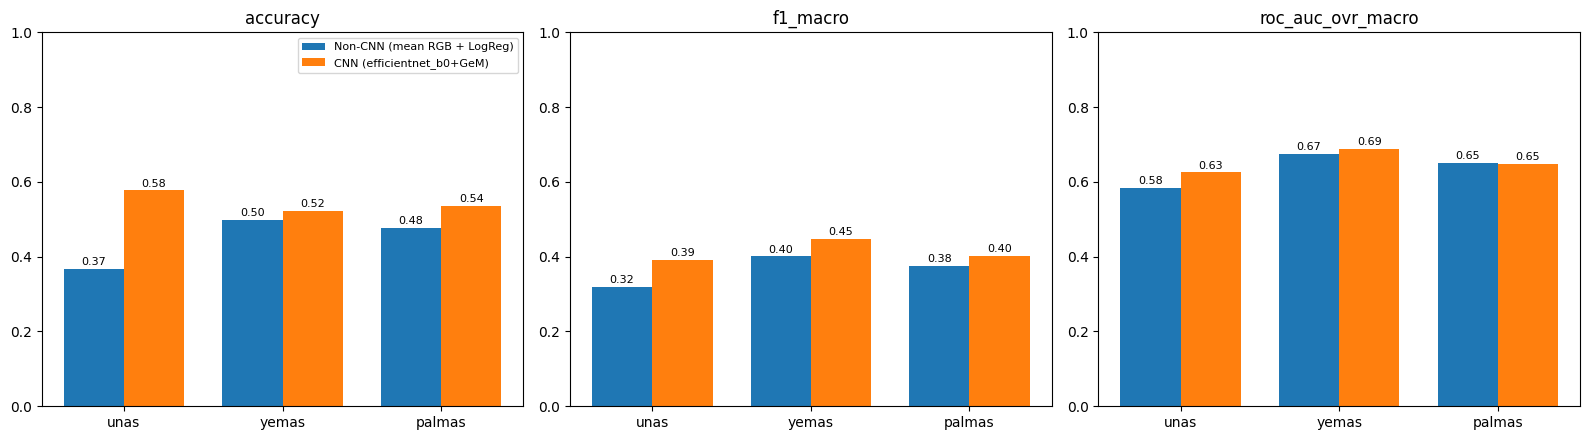

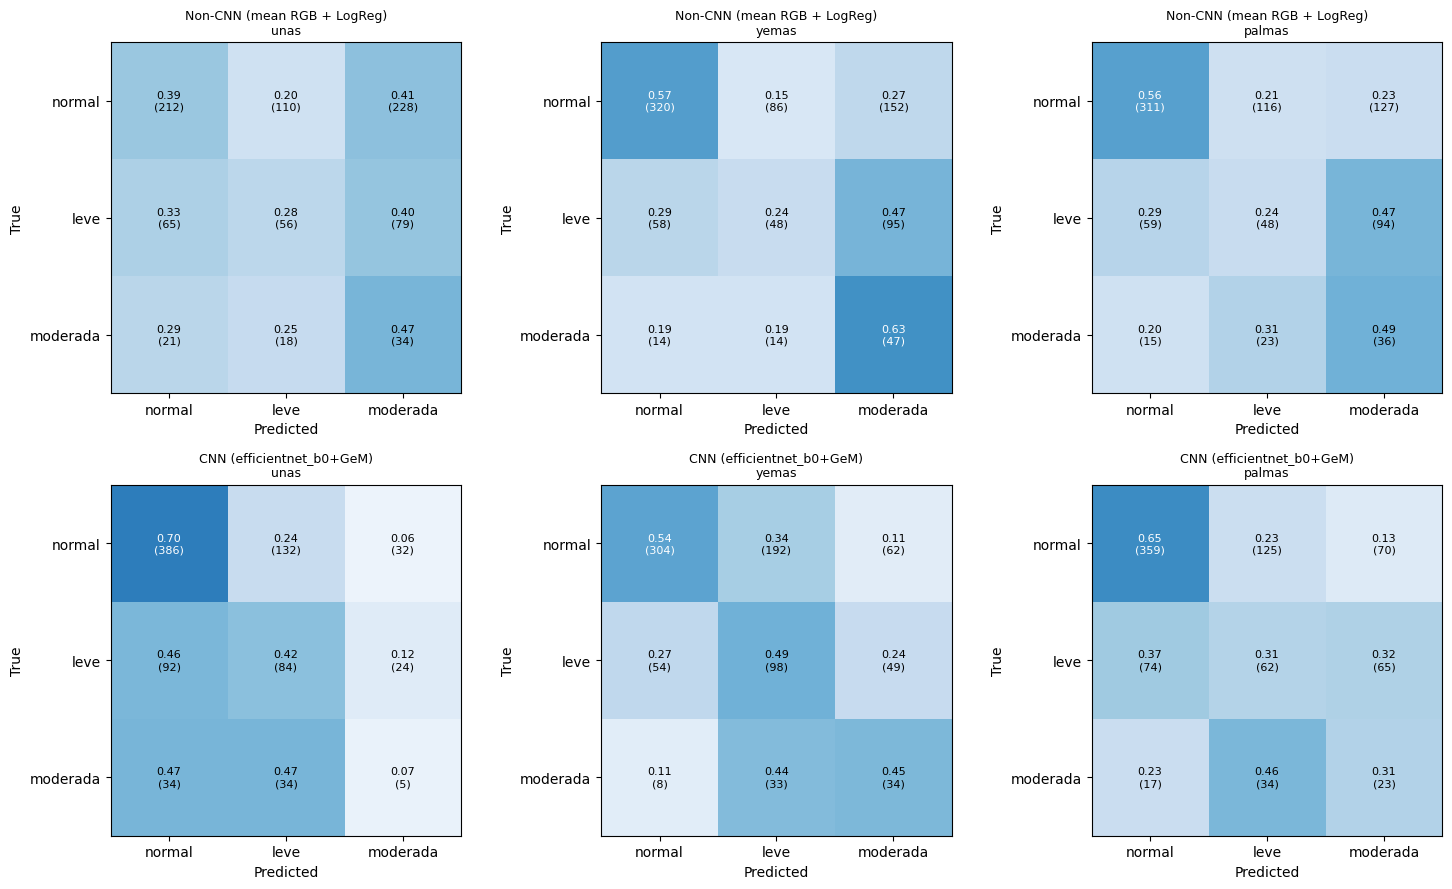

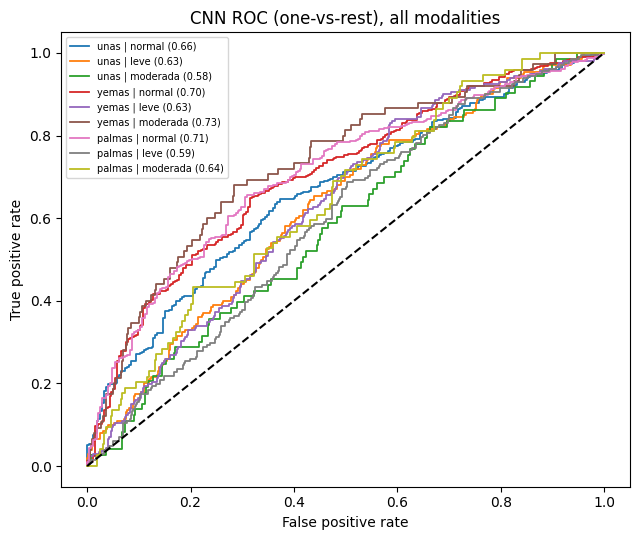

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5)); w = 0.38
for a, met in zip(ax, ["accuracy", "f1_macro", "roc_auc_ovr_macro"]):
    for j, (name, key) in enumerate(MODELS):
        vals = [res[m][key][met] for m in done]
        bars = a.bar(np.arange(len(done)) + (j - 0.5) * w, vals, w, label=name)
        for b, v in zip(bars, vals): a.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
    a.set_xticks(range(len(done))); a.set_xticklabels(done); a.set_ylim(0, 1); a.set_title(met)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{ALL_OUT}/comparison_bar_chart.png", dpi=200); plt.show()

fig, axes = plt.subplots(2, len(done), figsize=(5 * len(done), 9), squeeze=False)
for r, (name, key) in enumerate(MODELS):
    for c, m in enumerate(done):
        cm = np.array(res[m]["cm_" + key]); cmn = cm / cm.sum(1, keepdims=True); a = axes[r, c]
        a.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        a.set_xticks(LABELS); a.set_xticklabels(CLASS_NAMES); a.set_yticks(LABELS); a.set_yticklabels(CLASS_NAMES)
        a.set_title(f"{name}\n{m}", fontsize=9); a.set_xlabel("Predicted"); a.set_ylabel("True")
        for i in LABELS:
            for j in LABELS:
                a.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.5 else "black")
plt.tight_layout(); plt.savefig(f"{ALL_OUT}/comparison_confusion_matrices.png", dpi=200); plt.show()

# combined ROC (CNN, macro-average one-vs-rest per modality)
plt.figure(figsize=(6.5, 5.5))
for m in done:
    g = pd.read_csv(f"{MET_ROOT}/{m}/cnn_participant_predictions.csv"); yb = label_binarize(g.y, classes=LABELS)
    for i in LABELS:
        fpr, tpr, _ = roc_curve(yb[:, i], g[PC].values[:, i]); plt.plot(fpr, tpr, lw=1.3, label=f"{m} | {CLASS_NAMES[i]} ({auc(fpr, tpr):.2f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("CNN ROC (one-vs-rest), all modalities"); plt.legend(fontsize=7); plt.tight_layout()
plt.savefig(f"{ALL_OUT}/comparison_roc_cnn.png", dpi=200); plt.show()

## Cell 16: Detailed report of each modality (saved figures: confusion matrix + ROC, learning curves)

 unas 


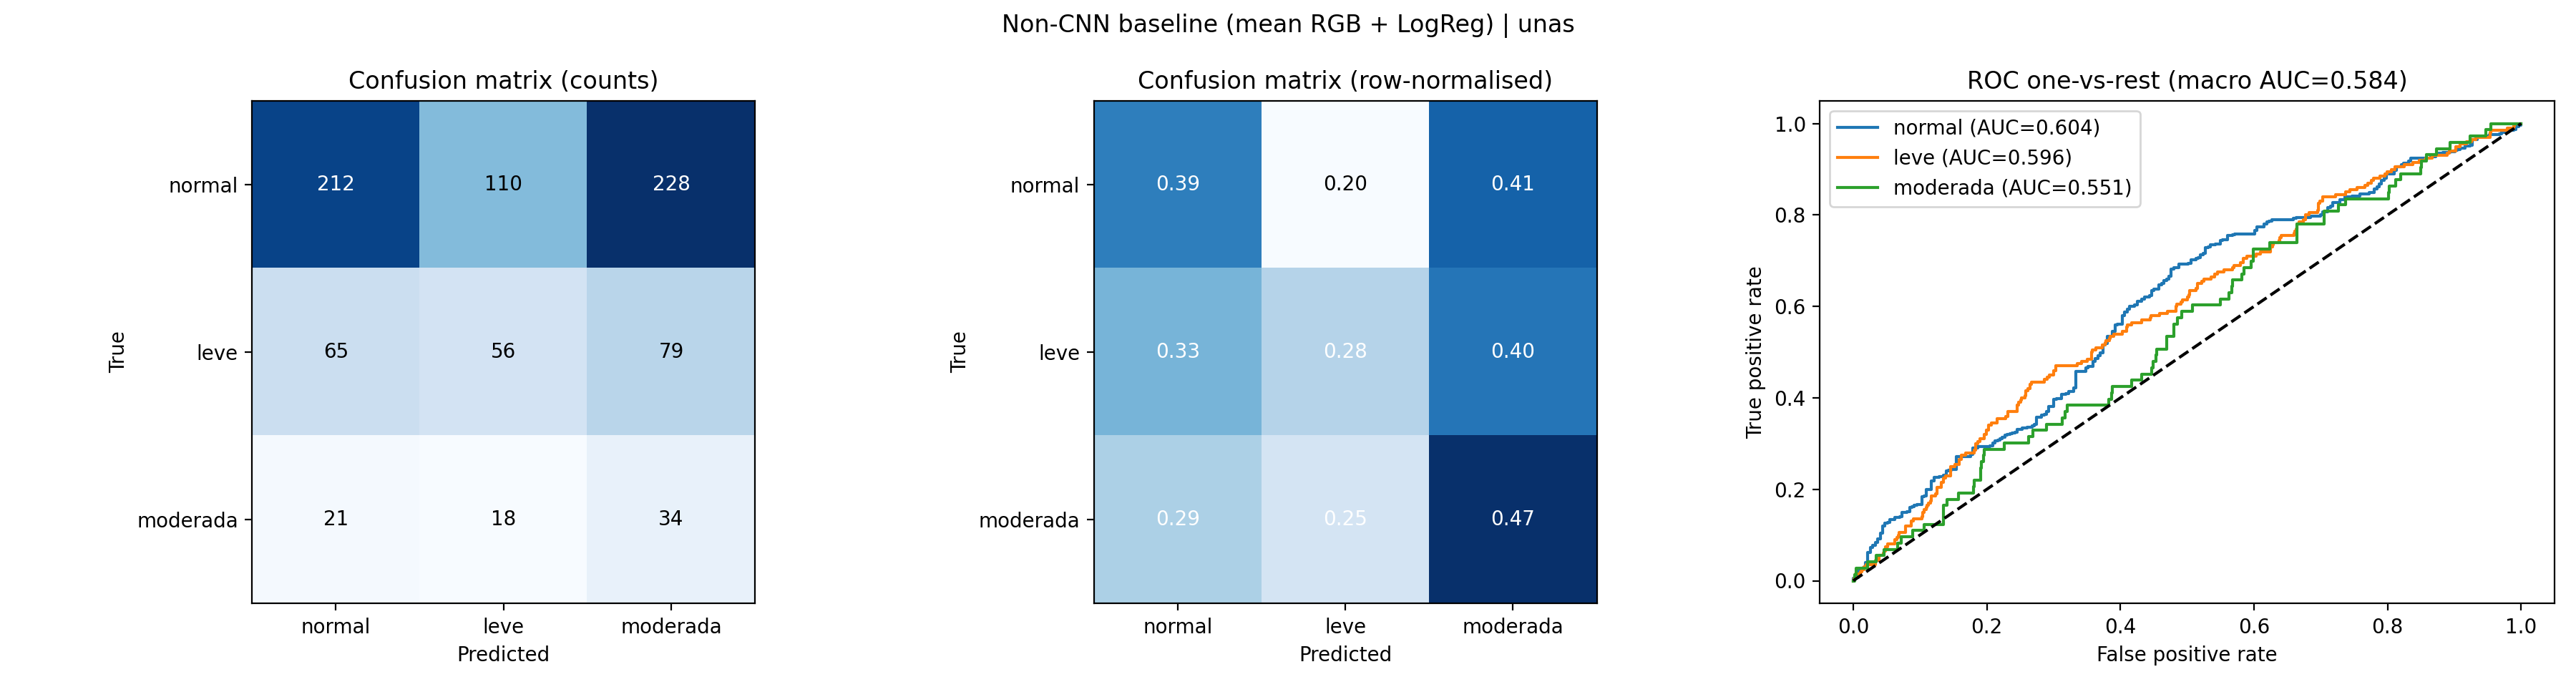

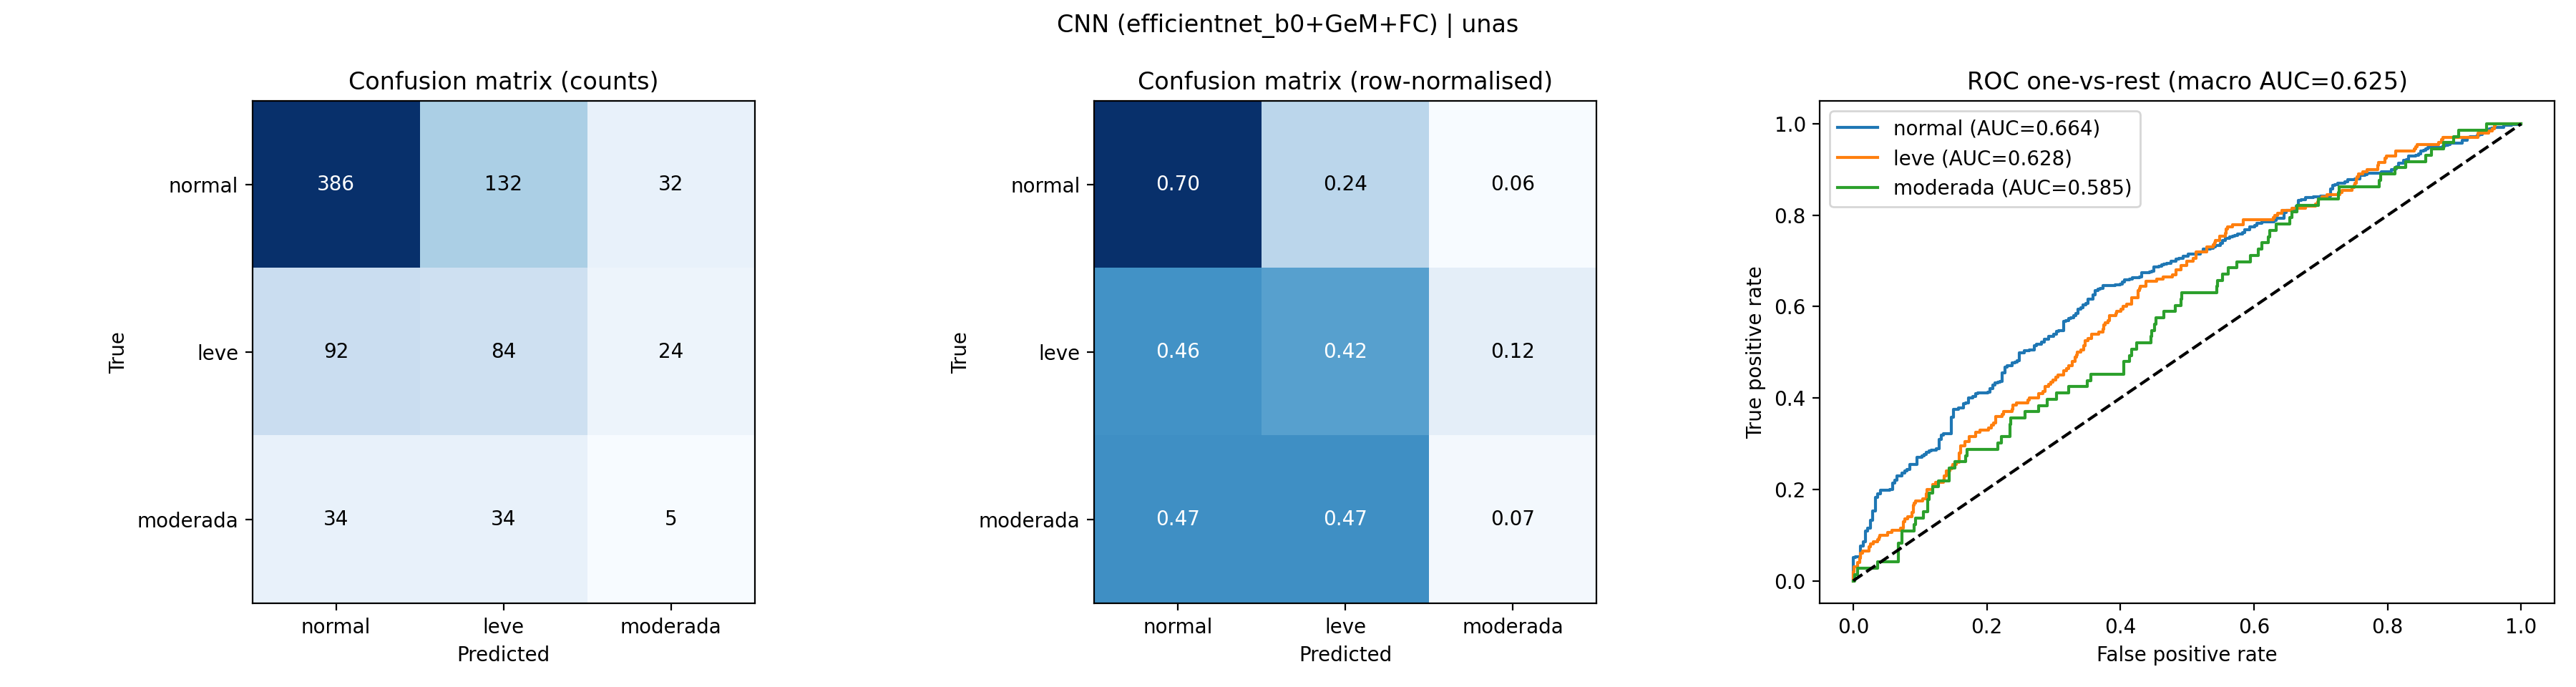

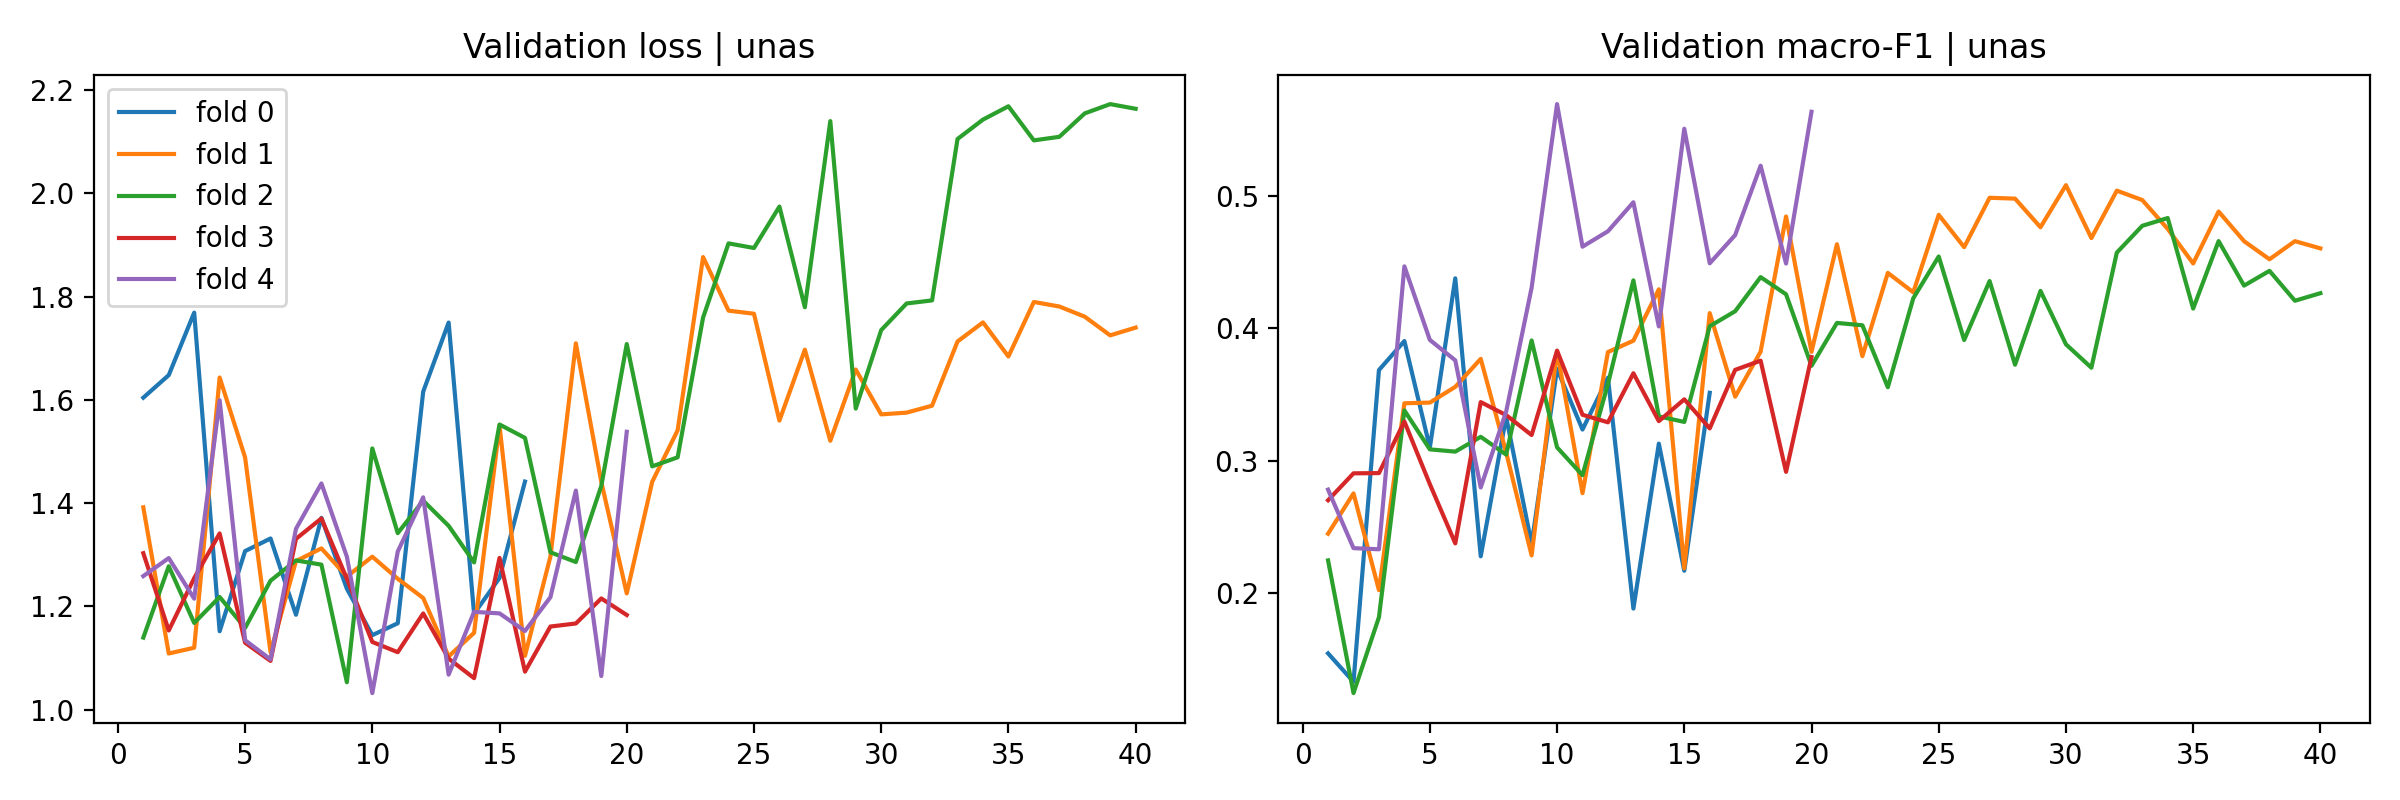

 yemas 


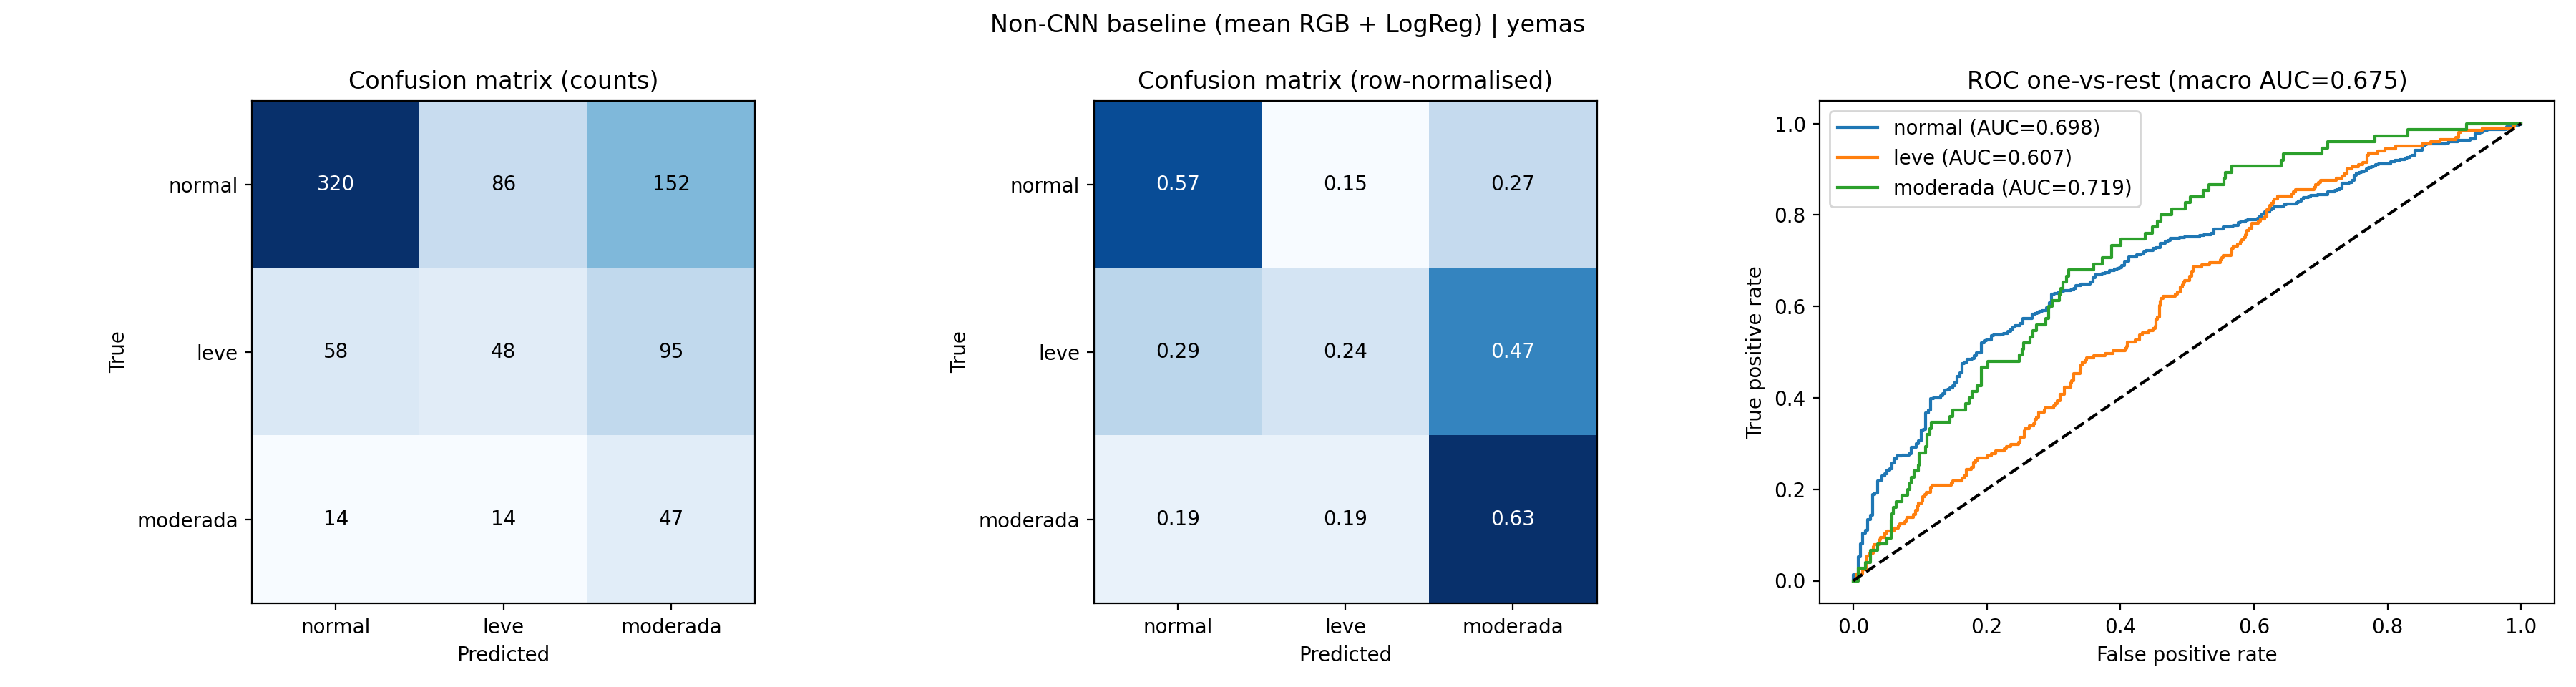

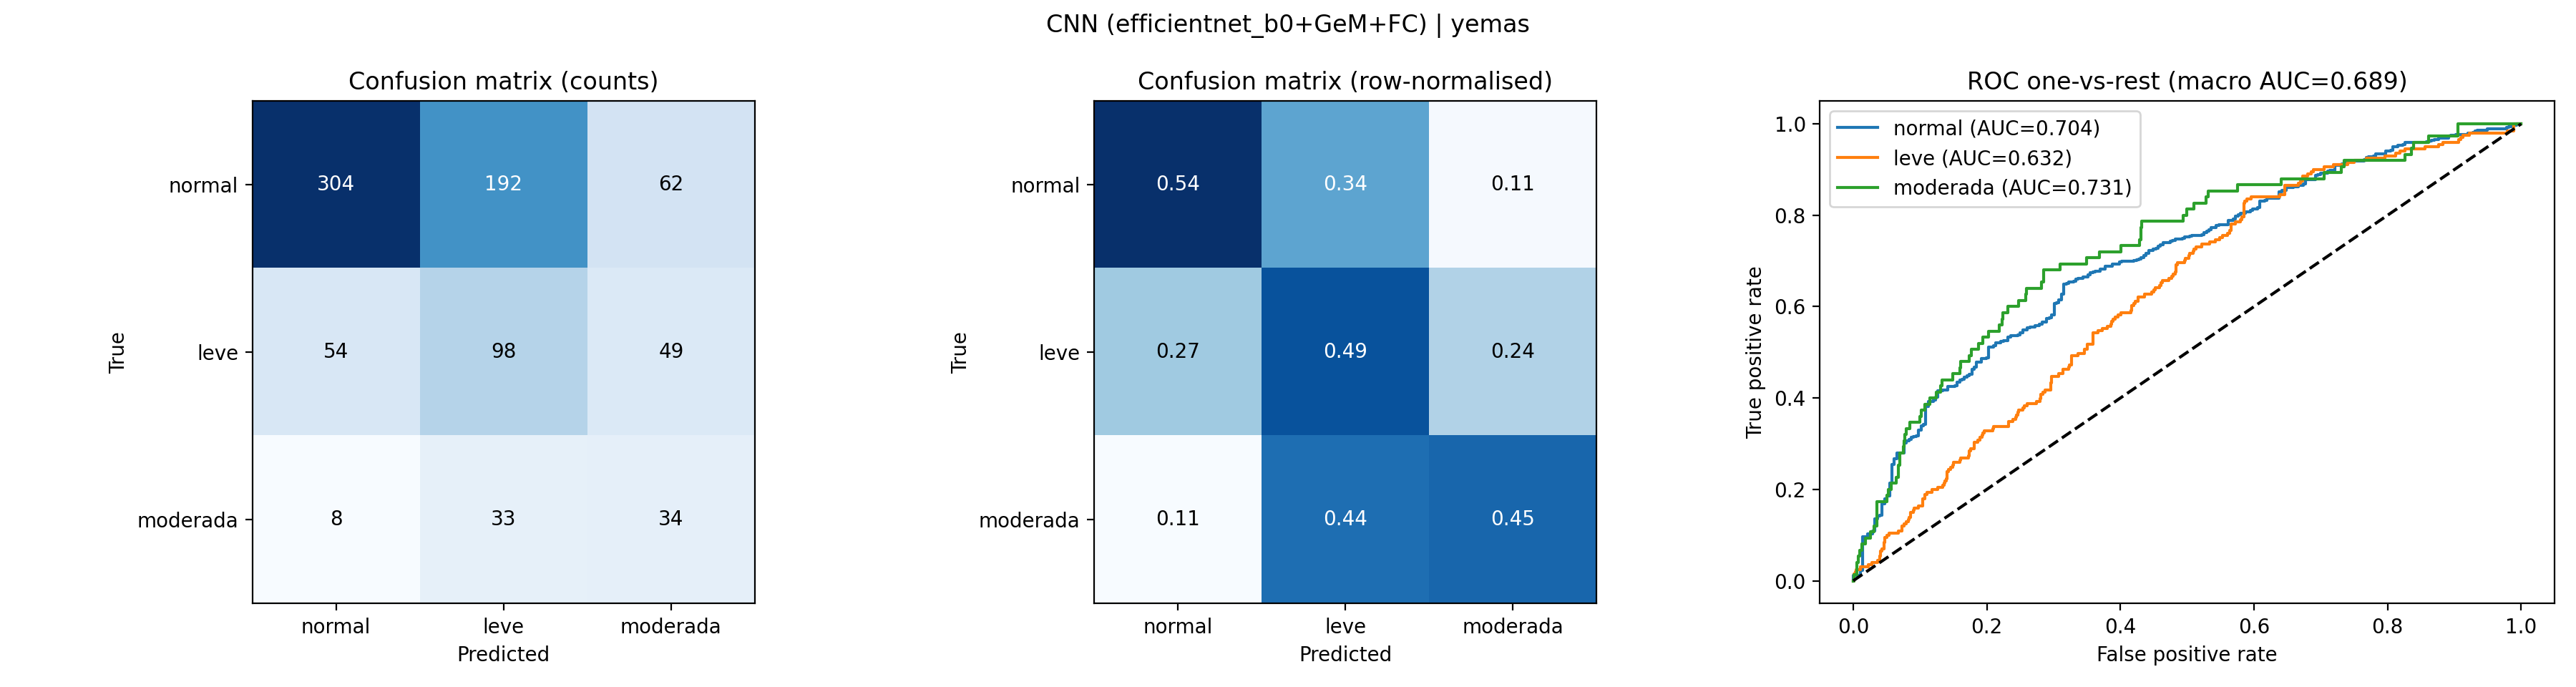

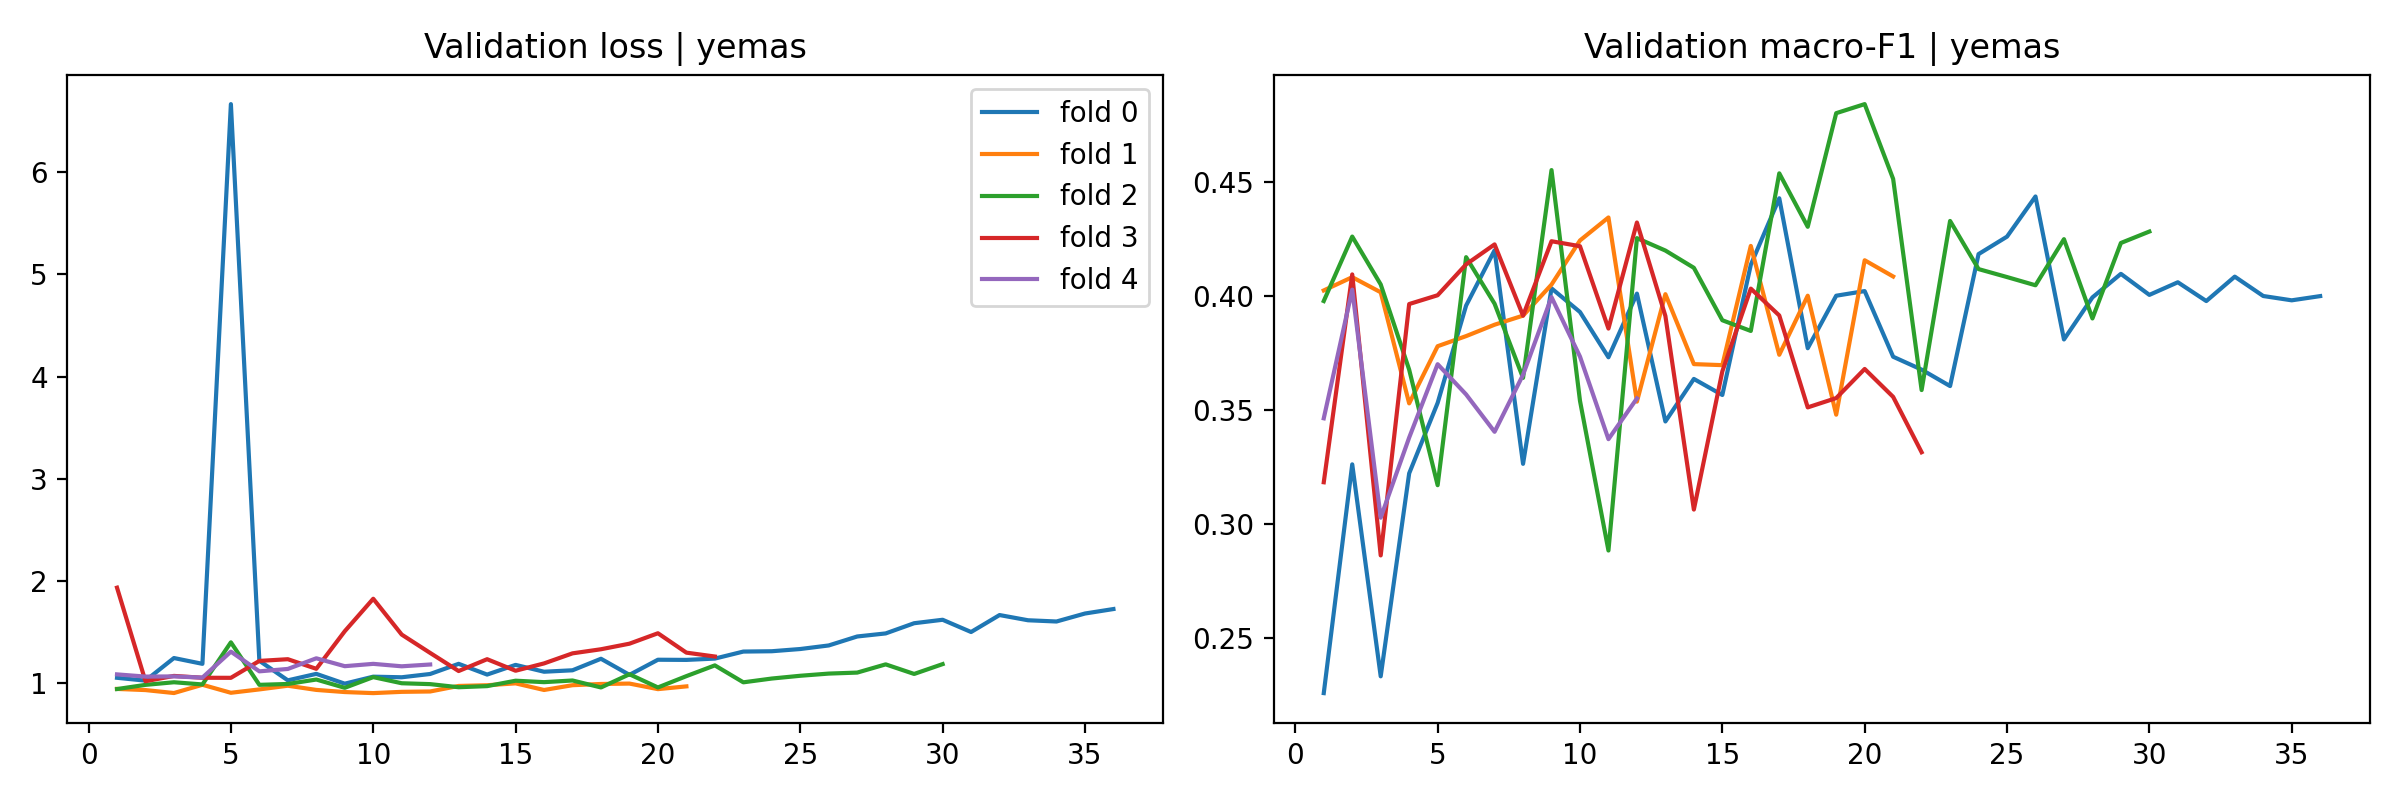

 palmas 


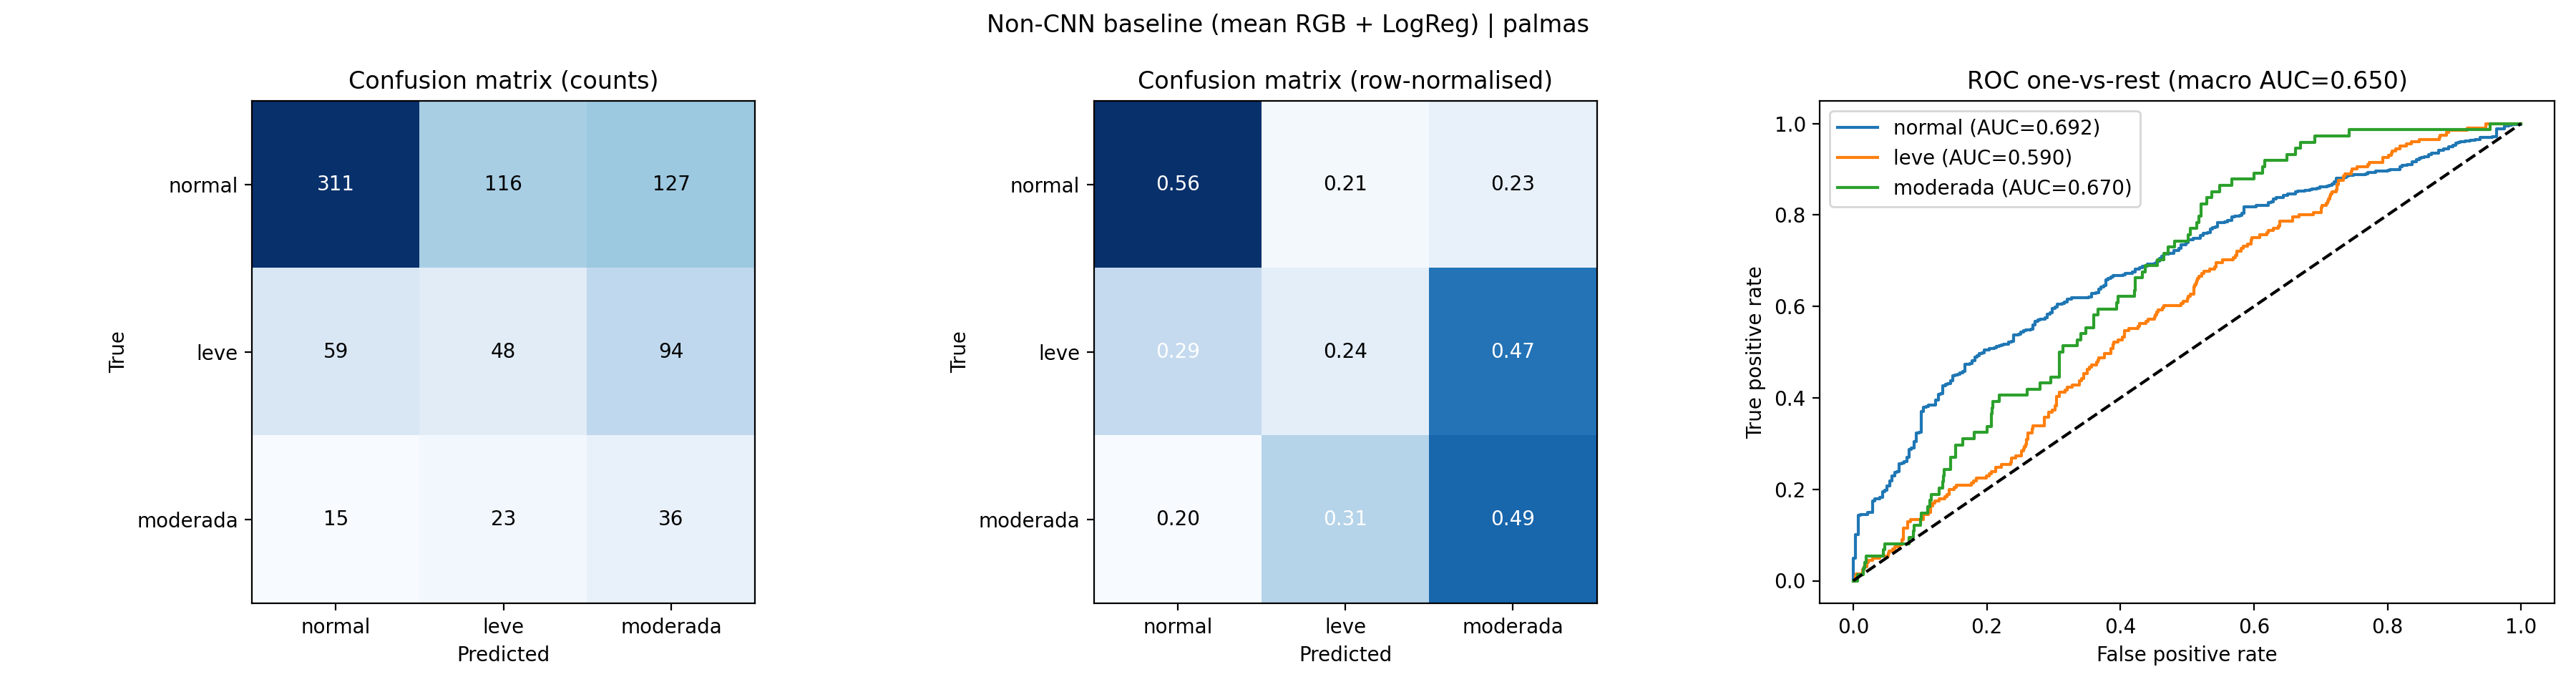

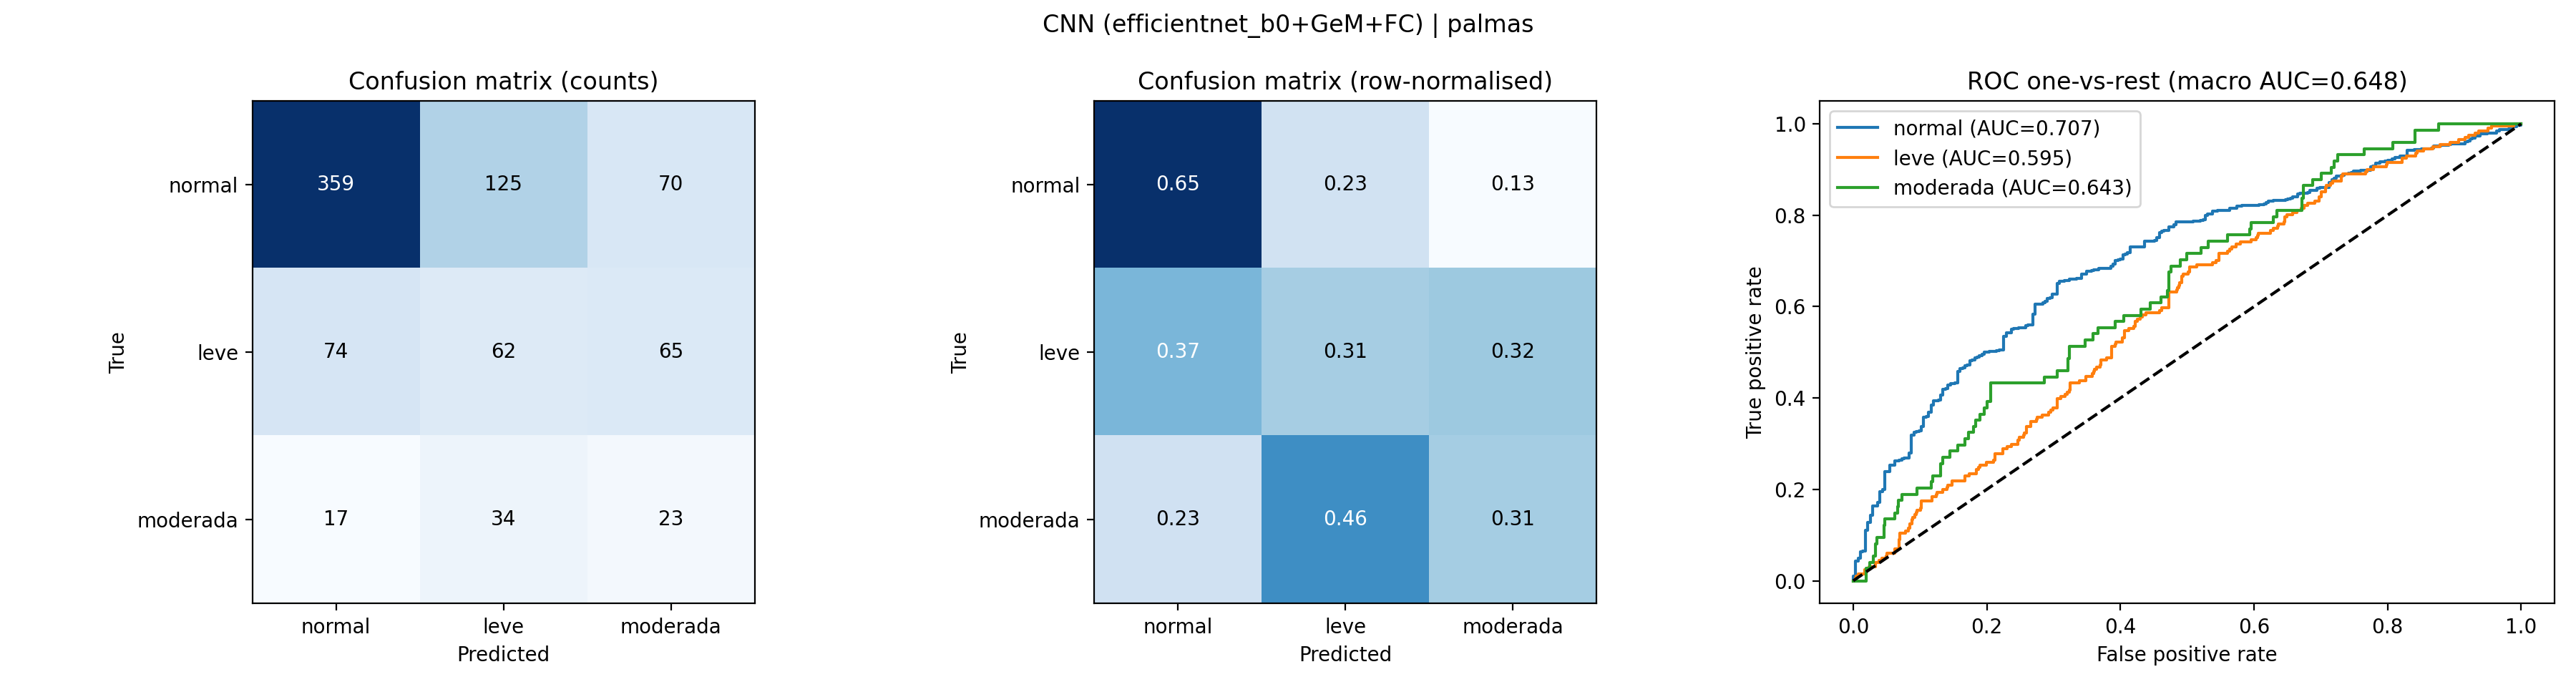

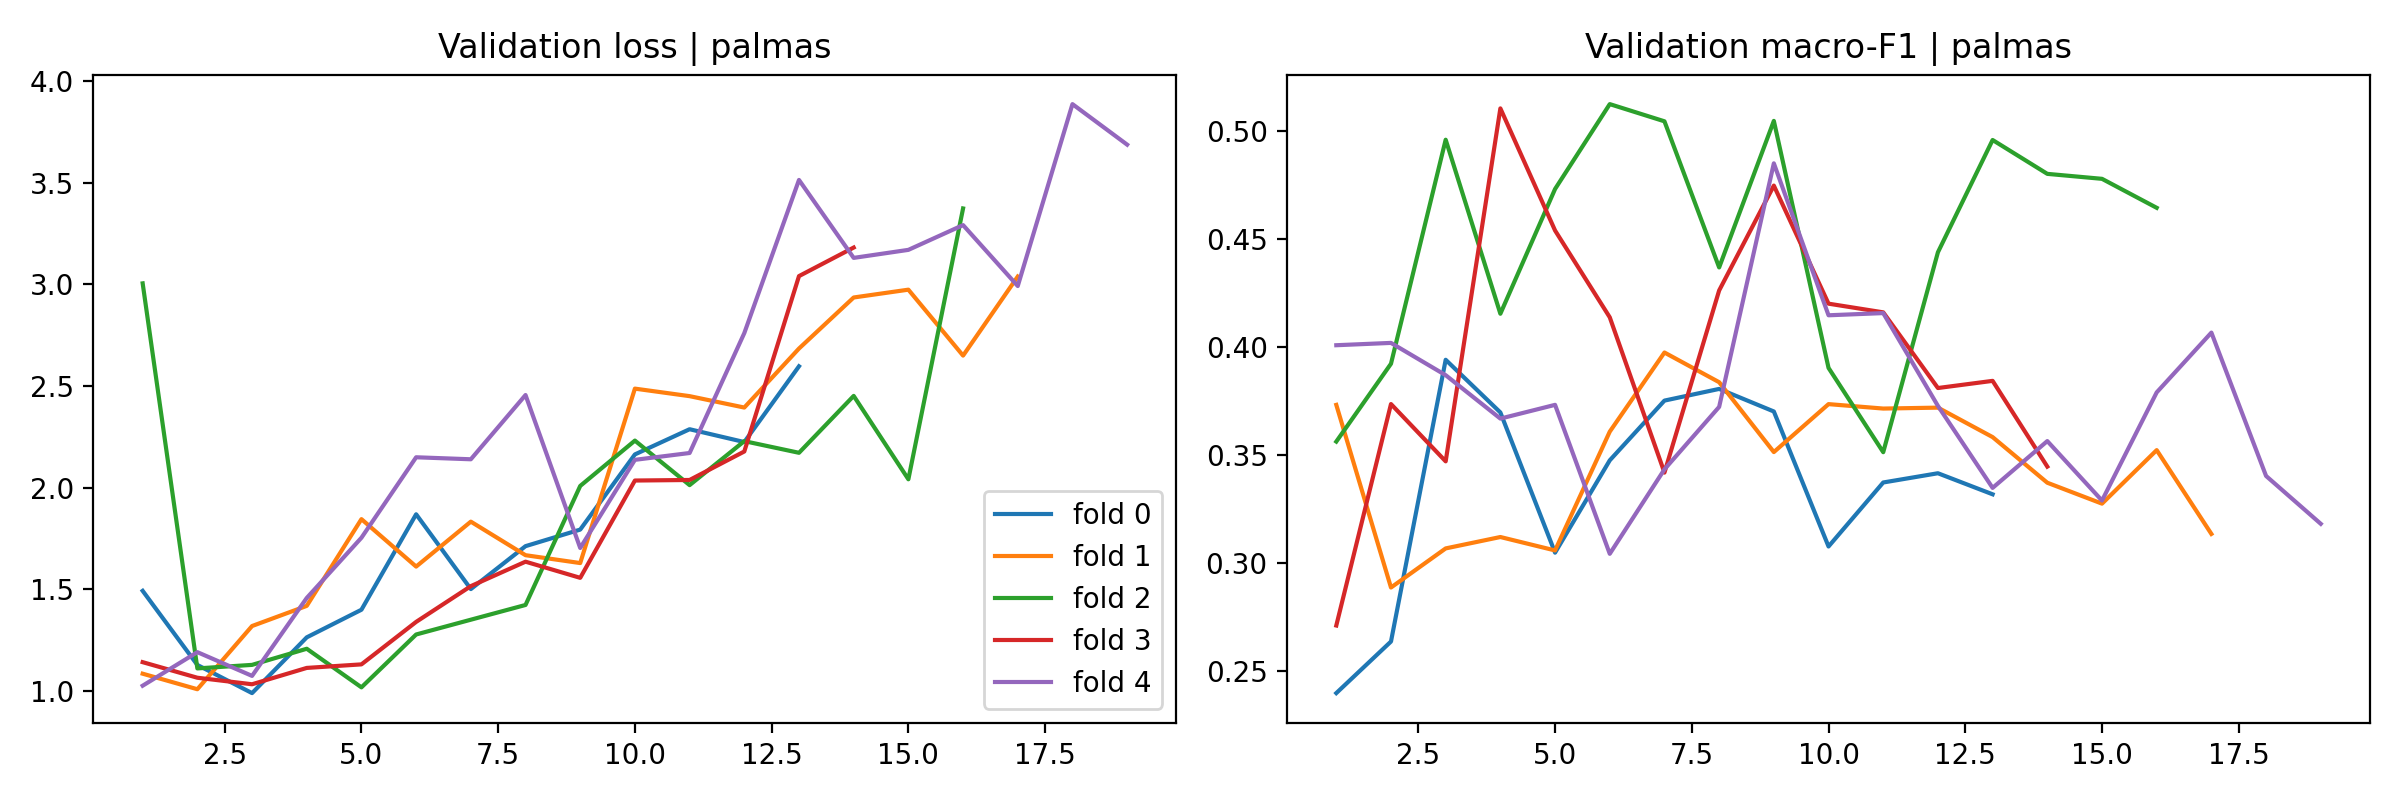

In [18]:
for m in done:
    print("=" * 80, "\n", m, "\n", "=" * 80)
    for f in ["baseline_meanRGB_LogReg_report.png", "cnn_report.png", "cnn_learning_curves.png"]:
        display(IPImage(f"{MET_ROOT}/{m}/{f}"))

## Cell 17: Grad-CAM for every modality (fold 0 model, one test image per class)

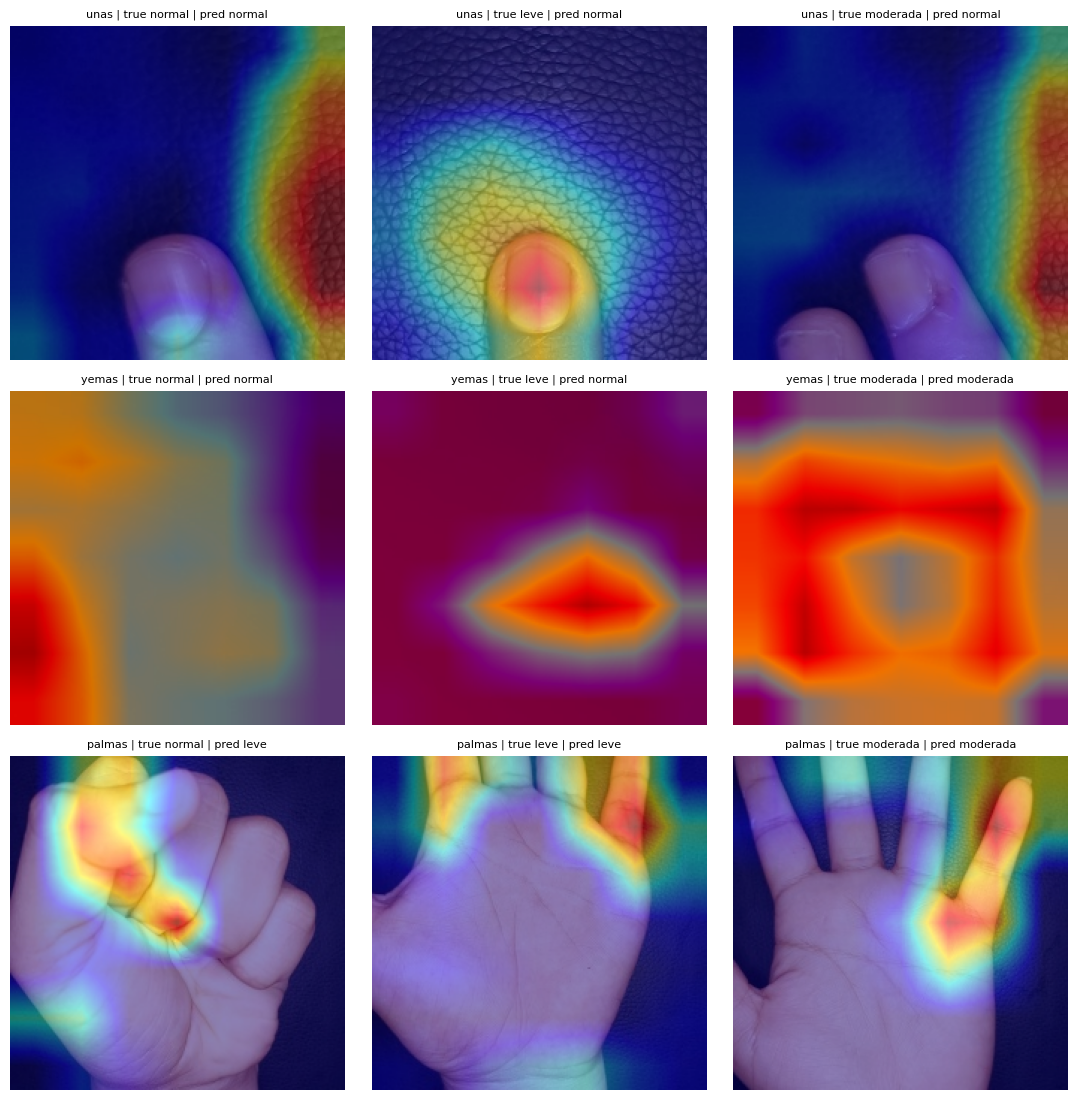

In [19]:
def gradcam_rows(mod, k=0):
    model = build_model().to(DEVICE)
    model.load_state_dict(torch.load(f"{CKPT_ROOT}/{mod}/fold{k}_best.pt", map_location=DEVICE)); model.eval()
    te = pd.read_csv(f"{CKPT_ROOT}/{mod}/cnn_fold{k}_preds.csv"); out = []
    for c in LABELS:
        p = te[te.y == c].sample(1, random_state=SEED).path.iloc[0]
        im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
        x = eval_tfms(image=im)["image"].unsqueeze(0).to(DEVICE)
        fmap = model.features(x); fmap.retain_grad(); logits = model.head(fmap); pred = int(logits.argmax(1))
        model.zero_grad(); logits[0, pred].backward()
        cam = F.relu((fmap.grad.mean((2, 3), keepdim=True) * fmap).sum(1))[0].detach().cpu().numpy()
        cam = cv2.resize(cam, (IMG_SIZE, IMG_SIZE)); cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        base = cv2.resize(im, (IMG_SIZE, IMG_SIZE))
        heat = cv2.cvtColor(cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
        out.append(((0.55 * base + 0.45 * heat).astype(np.uint8), c, pred))
    del model; torch.cuda.empty_cache(); return out

fig, axes = plt.subplots(len(done), 3, figsize=(11, 3.7 * len(done)), squeeze=False)
for r, m in enumerate(done):
    for c, (ov, t, p) in enumerate(gradcam_rows(m)):
        axes[r, c].imshow(ov); axes[r, c].axis("off"); axes[r, c].set_title(f"{m} | true {CLASS_NAMES[t]} | pred {CLASS_NAMES[p]}", fontsize=8)
plt.tight_layout(); plt.savefig(f"{ALL_OUT}/gradcam_all_modalities.png", dpi=200); plt.show()

## Cell 18: Zip everything for download

In [20]:
zp = shutil.make_archive(f"{WORK}/ALL_RESULTS", "zip", MET_ROOT)
print("Metrics zip:", zp)
print("\nFiles in", ALL_OUT)
for f in sorted(os.listdir(ALL_OUT)): print(" -", f)

Metrics zip: /kaggle/working/ALL_RESULTS.zip

Files in /kaggle/working/metrics_all/ALL_modalities
 - comparison_bar_chart.png
 - comparison_confusion_matrices.png
 - comparison_roc_cnn.png
 - final_comparison_all_modalities.csv
 - gradcam_all_modalities.png
 - per_class_all_modalities.csv
